# Visualisasi Tujuan 3 — Implementasi dan Evaluasi Sistem QA Berbasis RAG (Bab 4.3)

Notebook ini hanya membaca artefak aktual di `Hasil/tujuan3`. Evaluasi RAGAS utama
tetap memakai protokol **end-to-end** untuk Llama dan benchmark DeepSeek. Bagian uji
performa memakai hanya baris Llama-3.2 fine-tuned dari keluaran terbaru `versi-final`
notebook 23b. Perencanaan adopsi dibaca dari keluaran terbaru `adopsi-bps`; kebutuhan
pengembangan model juga dibatasi ke Llama-3.2. Angka asumsi dan proyeksi
tetap ditandai sebagai perencanaan, bukan hasil uji produksi. Tidak ada nilai hasil yang
digunakan sebagai fallback atau ditulis langsung di dalam grafik.

Cakupan:

- arsitektur pipeline aktual dari manifest dan hasil preflight;
- evaluasi ablasi RAGAS end-to-end;
- evaluasi skenario, gaya bahasa, dan kesalahan ketik;
- benchmark sistem versi akhir, kondisi cache, throughput, dan sumber daya;
- pengujian streaming dan black-box;
- kebutuhan operasional, pengembangan model, dan pembuatan dataset untuk adopsi BPS.


## Setup dan pemuatan artefak hasil


In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
%cd /content/drive/MyDrive/Skripsi/SourceCode/SkripsiNabil/Hasil/tujuan3

/content/drive/MyDrive/Skripsi/SourceCode/SkripsiNabil/Hasil/tujuan3


In [26]:
%matplotlib inline
import json
import re
import textwrap
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Patch

plt.rcParams.update({
    "font.family": "serif", "font.size": 10, "axes.grid": True,
    "grid.alpha": 0.3, "axes.axisbelow": True, "figure.dpi": 150,
})

C_BLUE, C_ORANGE, C_GREEN = "#2c6fbb", "#e08a1e", "#3a7d44"
C_RED, C_PURPLE, C_GRAY = "#c0392b", "#8e5ea2", "#7f8c8d"
MODEL_UTAMA = "llama3.2-finetuned"
ARSITEKTUR_UTAMA = "llama3.2"
MODEL_BENCHMARK = "deepseek-flash"
ARSITEKTUR_BENCHMARK = "deepseek"
MODEL_GEMMA = "gemma2-finetuned"
ARSITEKTUR_GEMMA = "gemma2"
MODEL_SKENARIO = [MODEL_UTAMA, MODEL_BENCHMARK]
MODEL_LABELS = {
    MODEL_UTAMA: "Llama-3.2 (fine-tuned)",
    ARSITEKTUR_UTAMA: "Llama-3.2",
    MODEL_BENCHMARK: "DeepSeek-Flash",
    ARSITEKTUR_BENCHMARK: "DeepSeek-Flash",
    MODEL_GEMMA: "Gemma-2 (fine-tuned)",
    ARSITEKTUR_GEMMA: "Gemma-2",
}
MODEL_COLORS = {
    MODEL_UTAMA: C_BLUE,
    ARSITEKTUR_UTAMA: C_BLUE,
    MODEL_BENCHMARK: C_ORANGE,
    ARSITEKTUR_BENCHMARK: C_ORANGE,
    MODEL_GEMMA: C_ORANGE,
    ARSITEKTUR_GEMMA: C_ORANGE,
}

def warna_model(kunci):
    return MODEL_COLORS.get(str(kunci), C_GRAY)

def temukan_root(mulai=Path.cwd()):
    mulai = Path(mulai).resolve()
    for kandidat in (mulai, *mulai.parents):
        if (kandidat / "Hasil" / "tujuan3").is_dir():
            return kandidat
    raise FileNotFoundError("Root proyek dengan Hasil/tujuan3 tidak ditemukan.")

PROJECT_ROOT = temukan_root()
DATA_TUJUAN3 = PROJECT_ROOT / "Hasil" / "tujuan3"

def hasil_t3(nama, wajib=False):
    # Artefak umum dibaca dari tingkat teratas. Keluaran benchmark final dan
    # adopsi memiliki pemilih run tersendiri agar nama file yang sama tidak ambigu.
    tujuan = DATA_TUJUAN3 / nama
    if wajib and not tujuan.exists():
        raise FileNotFoundError(f"Artefak wajib belum ada di Hasil/tujuan3: {nama}")
    return tujuan

def baca_json(nama, wajib=False):
    p = hasil_t3(nama, wajib=wajib)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None

def baca_csv(nama, wajib=False):
    p = hasil_t3(nama, wajib=wajib)
    return pd.read_csv(p) if p.exists() else None

def run_terbaru(subfolder, berkas_wajib):
    root = DATA_TUJUAN3 / subfolder
    kandidat = sorted(
        p for p in root.iterdir()
        if p.is_dir() and all((p / nama).is_file() for nama in berkas_wajib)
    ) if root.is_dir() else []
    if not kandidat:
        raise FileNotFoundError(
            f"Tidak ada run lengkap di {root}; wajib: {', '.join(berkas_wajib)}"
        )
    return kandidat[-1]

def baca_csv_path(path):
    return pd.read_csv(path, encoding="utf-8-sig")

def baca_json_path(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))

def baca_ragas_raw():
    # Utamakan CSV langsung di folder hasil. Untuk keluaran lama, baca CSV yang
    # sama langsung dari arsip nb20.zip tanpa mengekstraknya ke folder kerja.
    csv_path = hasil_t3("ragas_raw.csv")
    if csv_path.exists():
        return pd.read_csv(csv_path)
    zip_path = hasil_t3("nb20.zip")
    if not zip_path.exists():
        return None
    with zipfile.ZipFile(zip_path) as arsip:
        kandidat = [n for n in arsip.namelist()
                     if n == "ragas_raw.csv" or n.endswith("/ragas_raw.csv")]
        if len(kandidat) != 1:
            raise RuntimeError(f"ragas_raw.csv dalam {zip_path.name} ambigu/tidak ditemukan: {kandidat}")
        with arsip.open(kandidat[0]) as stream:
            return pd.read_csv(stream)

def lewati(pesan):
    print(f"[DILEWATI] {pesan}")

def label_model(kunci):
    return MODEL_LABELS.get(str(kunci), str(kunci).replace("_", " "))

def label_skenario(kunci):
    return re.sub(r"^\d+_", "", str(kunci)).replace("_", " ").title()

manifest = baca_json("scenario_generation_manifest.json", wajib=True)
preflight = baca_json("preflight.json", wajib=True)
functional_results = baca_json("functional_results.json", wajib=True)
stream_result = baca_json("stream_stage_test.json", wajib=True)

FINAL_RUN = run_terbaru(
    "versi-final",
    ["system_performance_all.csv", "system_performance_environment.json",
     "coverage.json", "capacity_profile.csv"],
)
ADOPTION_RUN = run_terbaru(
    "adopsi-bps",
    ["kebutuhan-operasional.csv", "kebutuhan-pengembangan-model.csv",
     "beban-pembuatan-dataset.csv", "cakupan-bukti-pengukuran.csv",
     "inventaris-artefak-sistem.csv", "asumsi-dan-sumber.json"],
)
perf_environment = baca_json_path(FINAL_RUN / "system_performance_environment.json")
coverage_system = baca_json_path(FINAL_RUN / "coverage.json")
performance_all = baca_csv_path(FINAL_RUN / "system_performance_all.csv")
capacity_profile_all = baca_csv_path(FINAL_RUN / "capacity_profile.csv")
adopsi_operasional = baca_csv_path(ADOPTION_RUN / "kebutuhan-operasional.csv")
adopsi_pengembangan_all = baca_csv_path(ADOPTION_RUN / "kebutuhan-pengembangan-model.csv")
adopsi_dataset = baca_csv_path(ADOPTION_RUN / "beban-pembuatan-dataset.csv")
adopsi_bukti = baca_csv_path(ADOPTION_RUN / "cakupan-bukti-pengukuran.csv")
adopsi_inventaris = baca_csv_path(ADOPTION_RUN / "inventaris-artefak-sistem.csv")
adopsi_metadata = baca_json_path(ADOPTION_RUN / "asumsi-dan-sumber.json")

scenario_results_all = baca_csv("scenario_results.csv", wajib=True)
scenario_by_model_all = baca_csv("scenario_ragas_summary_by_model.csv", wajib=True)
scenario_by_scenario_all = baca_csv("scenario_ragas_summary_by_scenario.csv", wajib=True)
scenario_coverage_all = baca_csv("scenario_ragas_coverage.csv", wajib=True)
style_comparison_all = baca_csv("scenario_ragas_style_comparison.csv", wajib=True)
typo_comparison_all = baca_csv("scenario_ragas_typo_comparison.csv", wajib=True)

ragas_summary_all = baca_csv("ragas_summary.csv")
ragas_deltas_all = baca_csv("ragas_paired_differences.csv")
ragas_raw_all = baca_ragas_raw()

def tanpa_model(df, kolom, nilai_dibuang, nama_artefak):
    if df is None:
        return None
    if kolom not in df.columns:
        raise ValueError(f"{nama_artefak} tidak memiliki kolom {kolom}")
    hasil = df[df[kolom].astype(str) != nilai_dibuang].copy()
    if hasil.empty:
        raise ValueError(f"Seluruh baris {nama_artefak} terbuang saat mengecualikan {nilai_dibuang}")
    return hasil

# Tujuan 3 menghapus Gemma-2, tetapi mempertahankan Llama sebagai SLM terbaik dan
# DeepSeek sebagai benchmark eksternal. Skor RAGAS utama dibatasi ke end-to-end.
scenario_results = tanpa_model(scenario_results_all, "model_key", MODEL_GEMMA, "scenario_results.csv")
scenario_by_model = tanpa_model(scenario_by_model_all, "model_key", MODEL_GEMMA, "scenario_ragas_summary_by_model.csv")
scenario_by_scenario = tanpa_model(scenario_by_scenario_all, "model_key", MODEL_GEMMA, "scenario_ragas_summary_by_scenario.csv")
scenario_coverage = tanpa_model(scenario_coverage_all, "model_key", MODEL_GEMMA, "scenario_ragas_coverage.csv")
style_comparison = tanpa_model(style_comparison_all, "model_key", MODEL_GEMMA, "scenario_ragas_style_comparison.csv")
typo_comparison = tanpa_model(typo_comparison_all, "model_key", MODEL_GEMMA, "scenario_ragas_typo_comparison.csv")
performance = performance_all[
    performance_all["model_key"].astype(str).eq(MODEL_UTAMA)
].copy()
capacity_profile = capacity_profile_all[
    capacity_profile_all["model_key"].astype(str).eq(MODEL_UTAMA)
].copy()
adopsi_pengembangan = adopsi_pengembangan_all[
    adopsi_pengembangan_all["model"].astype(str).eq(ARSITEKTUR_UTAMA)
].copy()
if performance.empty or capacity_profile.empty or adopsi_pengembangan.empty:
    raise ValueError("Artefak terbaru tidak memiliki keluaran lengkap untuk Llama-3.2")
if not performance["test_scope"].astype(str).eq("e2e_system_final").all():
    raise ValueError("CSV performa Llama terpilih bukan keluaran e2e_system_final dari notebook 23b")

if ragas_summary_all is None:
    ragas_summary = None
else:
    ragas_summary = tanpa_model(ragas_summary_all, "architecture", ARSITEKTUR_GEMMA, "ragas_summary.csv")
    ragas_summary = ragas_summary[ragas_summary["protocol"].astype(str) == "end_to_end"].copy()
    if ragas_summary.empty:
        raise ValueError("ragas_summary.csv tidak memiliki baris end_to_end setelah Gemma-2 dikeluarkan")

if ragas_deltas_all is None:
    ragas_deltas = None
else:
    comparison = ragas_deltas_all["comparison"].astype(str)
    ragas_deltas = ragas_deltas_all[
        ~comparison.str.contains(ARSITEKTUR_GEMMA, regex=False)
        & ~comparison.str.contains("controlled", case=False, regex=False)
    ].copy()
    if ragas_deltas.empty:
        raise ValueError("ragas_paired_differences.csv tidak memiliki delta end-to-end non-Gemma")

if ragas_raw_all is None:
    ragas_raw = None
else:
    kolom_raw = {"record_id", "architecture", "condition", "protocol", "answer_relevancy"}
    kurang_raw = sorted(kolom_raw - set(ragas_raw_all.columns))
    if kurang_raw:
        raise ValueError(f"ragas_raw.csv tidak memiliki kolom wajib: {kurang_raw}")
    ragas_raw = ragas_raw_all[
        (ragas_raw_all["architecture"].astype(str) == ARSITEKTUR_UTAMA)
        & (ragas_raw_all["protocol"].astype(str) == "end_to_end")
    ].copy()
    if ragas_raw.empty:
        raise ValueError("ragas_raw.csv tidak memuat evaluasi end-to-end Llama-3.2")

print(f"Sumber data             : {DATA_TUJUAN3}")
print("Cakupan model RAGAS     : Llama-3.2 + DeepSeek-Flash (Gemma-2 dikeluarkan)")
print("Protokol RAGAS tampil   : end_to_end")
print(f"Hasil skenario          : {len(scenario_results):,} baris")
print(f"Run performa final      : {FINAL_RUN.name}")
print(f"Pengukuran performa     : {len(performance):,} baris; {performance['model_key'].nunique()} model")
print(f"Profil concurrency      : {len(capacity_profile):,} baris")
print(f"Run adopsi BPS          : {ADOPTION_RUN.name}")
print(f"Kasus uji fungsional    : {len(functional_results):,}")
print(f"Ringkasan RAGAS e2e     : {'tersedia' if ragas_summary is not None else 'belum tersedia'}")
print(f"Delta RAGAS e2e         : {'tersedia' if ragas_deltas is not None else 'belum tersedia'}")
print(f"Skor mentah berpasangan : {'tersedia' if ragas_raw is not None else 'belum tersedia'}")


Sumber data             : /content/drive/MyDrive/Skripsi/SourceCode/SkripsiNabil/Hasil/tujuan3
Cakupan model RAGAS     : Llama-3.2 + DeepSeek-Flash (Gemma-2 dikeluarkan)
Protokol RAGAS tampil   : end_to_end
Hasil skenario          : 40 baris
Run performa final      : 20261012-200440-99c5f27b
Pengukuran performa     : 12 baris; 1 model
Profil concurrency      : 3 baris
Run adopsi BPS          : 20261012-202040-585b91b4
Kasus uji fungsional    : 7
Ringkasan RAGAS e2e     : tersedia
Delta RAGAS e2e         : tersedia
Skor mentah berpasangan : tersedia


## 1. Arsitektur dan alur pipeline aktual

Tahapan pipeline dan konfigurasi diambil dari `scenario_generation_manifest.json`,
`preflight.json`, dan `system_performance_environment.json`. Gemma-2 dikeluarkan; Llama
dipertahankan sebagai SLM terbaik dan DeepSeek sebagai benchmark eksternal RAGAS.


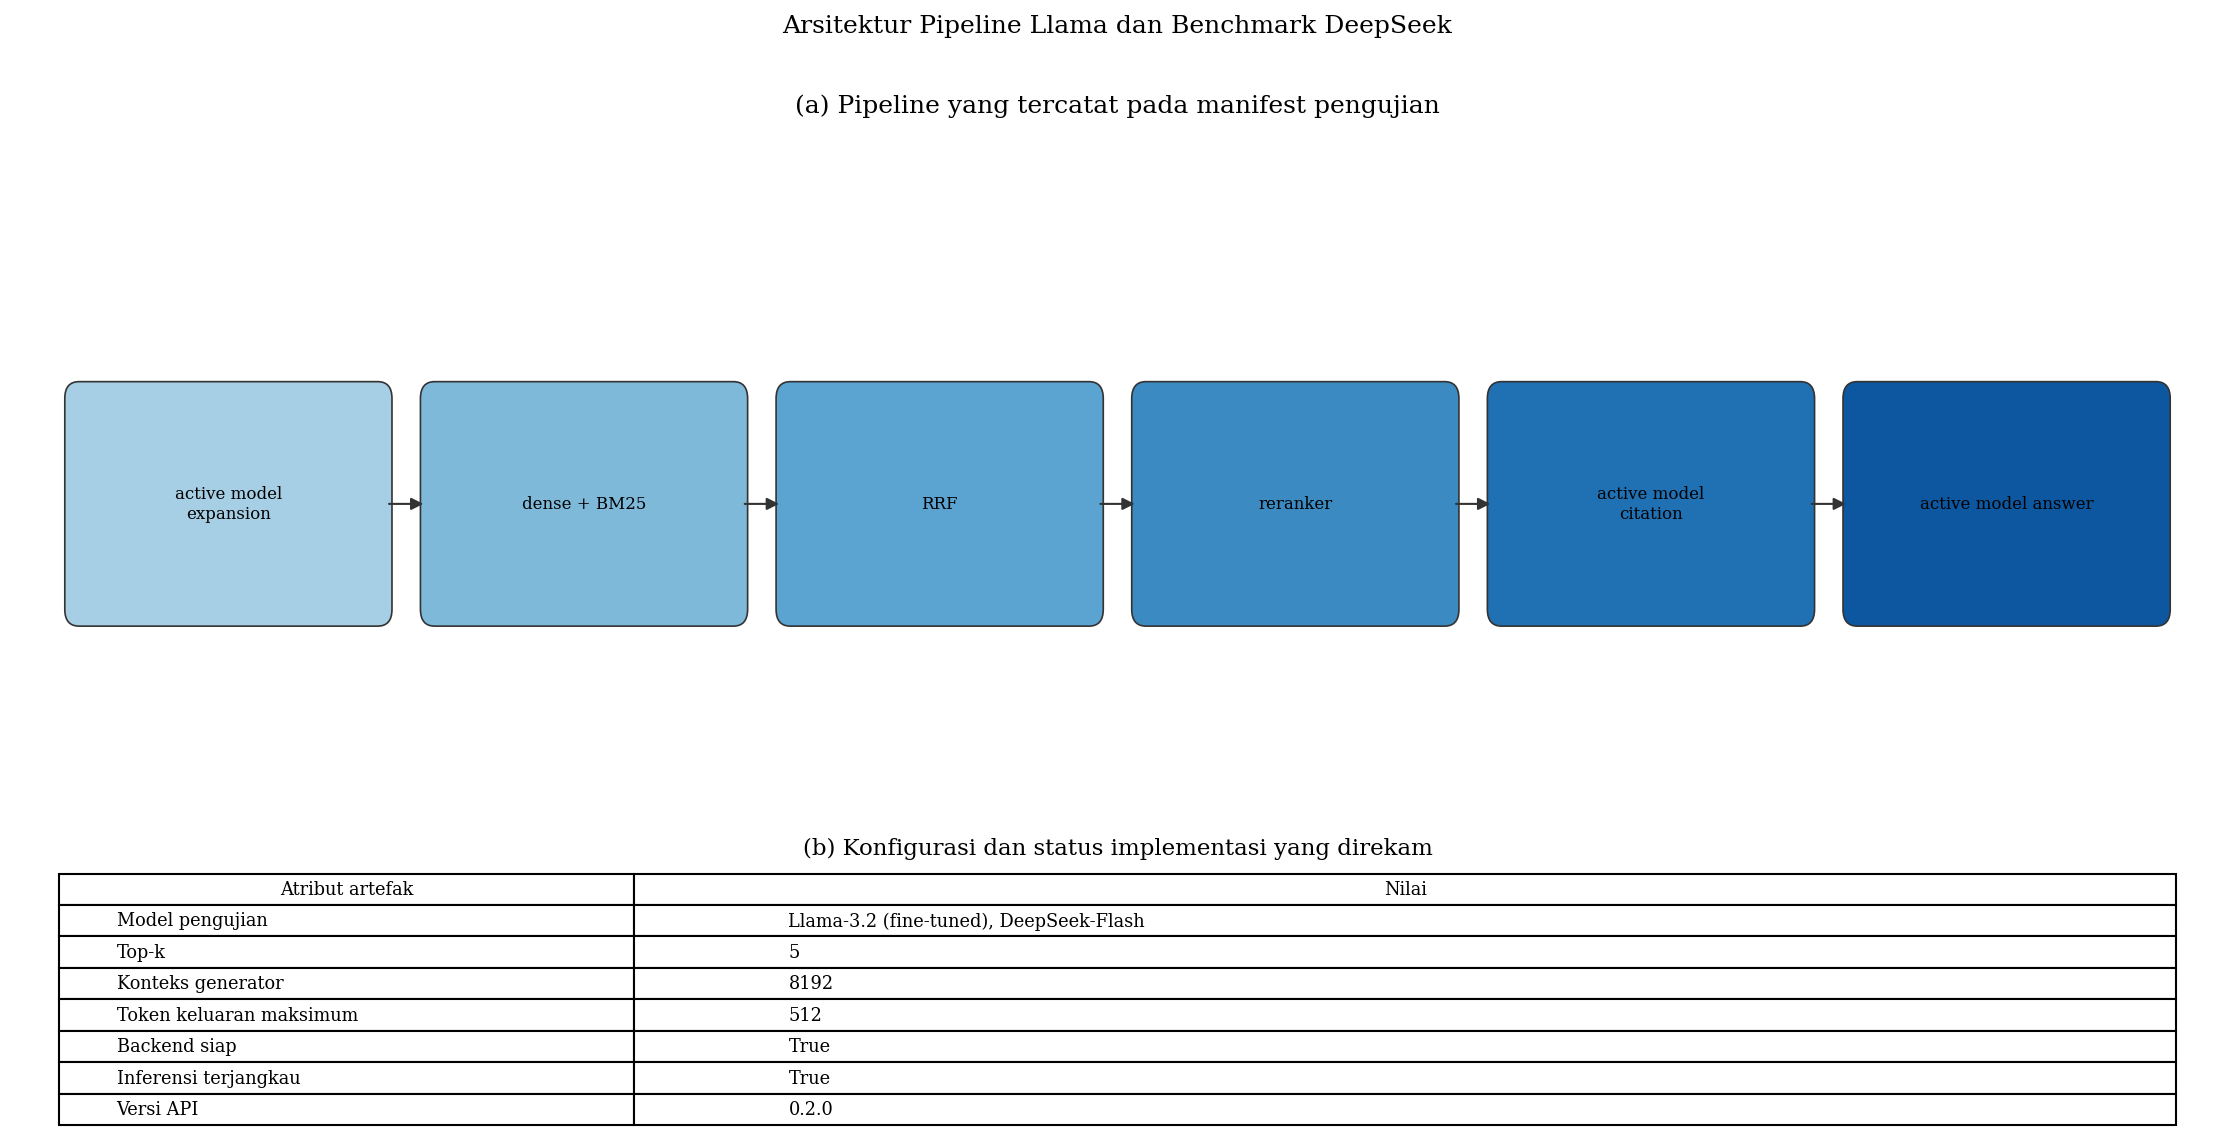

In [27]:
def fig1_pipeline_aktual():
    pipeline_text = manifest["pipeline"]
    tahap = [x.strip() for x in pipeline_text.split("->") if x.strip()]
    n = len(tahap)
    fig, axes = plt.subplots(2, 1, figsize=(15, 7.5), gridspec_kw={"height_ratios": [2.2, 1]})

    ax = axes[0]
    ax.set_xlim(-.6, n - .4); ax.set_ylim(-.7, .9); ax.axis("off")
    warna = plt.cm.Blues(np.linspace(.35, .85, max(n, 2)))
    kotak = []
    for i, nama in enumerate(tahap):
        teks = textwrap.fill(nama.replace("+", " + "), width=20)
        b = FancyBboxPatch((i - .42, -.25), .84, .5, boxstyle="round,pad=.04",
                           facecolor=warna[i], edgecolor="#333333", linewidth=.8)
        ax.add_patch(b); kotak.append(b)
        ax.text(i, 0, teks, ha="center", va="center", fontsize=8)
        if i:
            ax.add_patch(FancyArrowPatch((i - 1 + .44, 0), (i - .44, 0),
                                         arrowstyle="-|>", mutation_scale=12,
                                         linewidth=1, color="#333333"))
    ax.set_title("(a) Pipeline yang tercatat pada manifest pengujian")

    ax = axes[1]; ax.axis("off"); ax.grid(False)
    health = preflight.get("health", {})
    isi = [
        ["Model pengujian", ", ".join(label_model(m) for m in MODEL_SKENARIO)],
        ["Top-k", manifest.get("top_k")],
        ["Konteks generator", manifest.get("num_ctx")],
        ["Token keluaran maksimum", manifest.get("max_new_tokens")],
        ["Backend siap", health.get("ready")],
        ["Inferensi terjangkau", health.get("inference_reachable")],
        ["Versi API", preflight.get("api_version")],
    ]
    tabel = ax.table(cellText=isi, colLabels=["Atribut artefak", "Nilai"],
                     loc="center", cellLoc="left", colWidths=[.25, .67], bbox=[.02, .01, .96, .82])
    tabel.auto_set_font_size(False); tabel.set_fontsize(8.5); tabel.scale(1, 1.45)
    ax.text(.5, .95, "(b) Konfigurasi dan status implementasi yang direkam",
        transform=ax.transAxes, ha="center", va="top", fontsize=11)
    fig.suptitle("Arsitektur Pipeline Llama dan Benchmark DeepSeek", y=1.01)
    plt.tight_layout(); plt.savefig("fig01_pipeline_aktual.png", bbox_inches="tight"); plt.show()

fig1_pipeline_aktual()


### Alur event streaming satu permintaan

Urutan dan waktunya berasal dari `stream_stage_test.json`, bukan dari diagram statis.


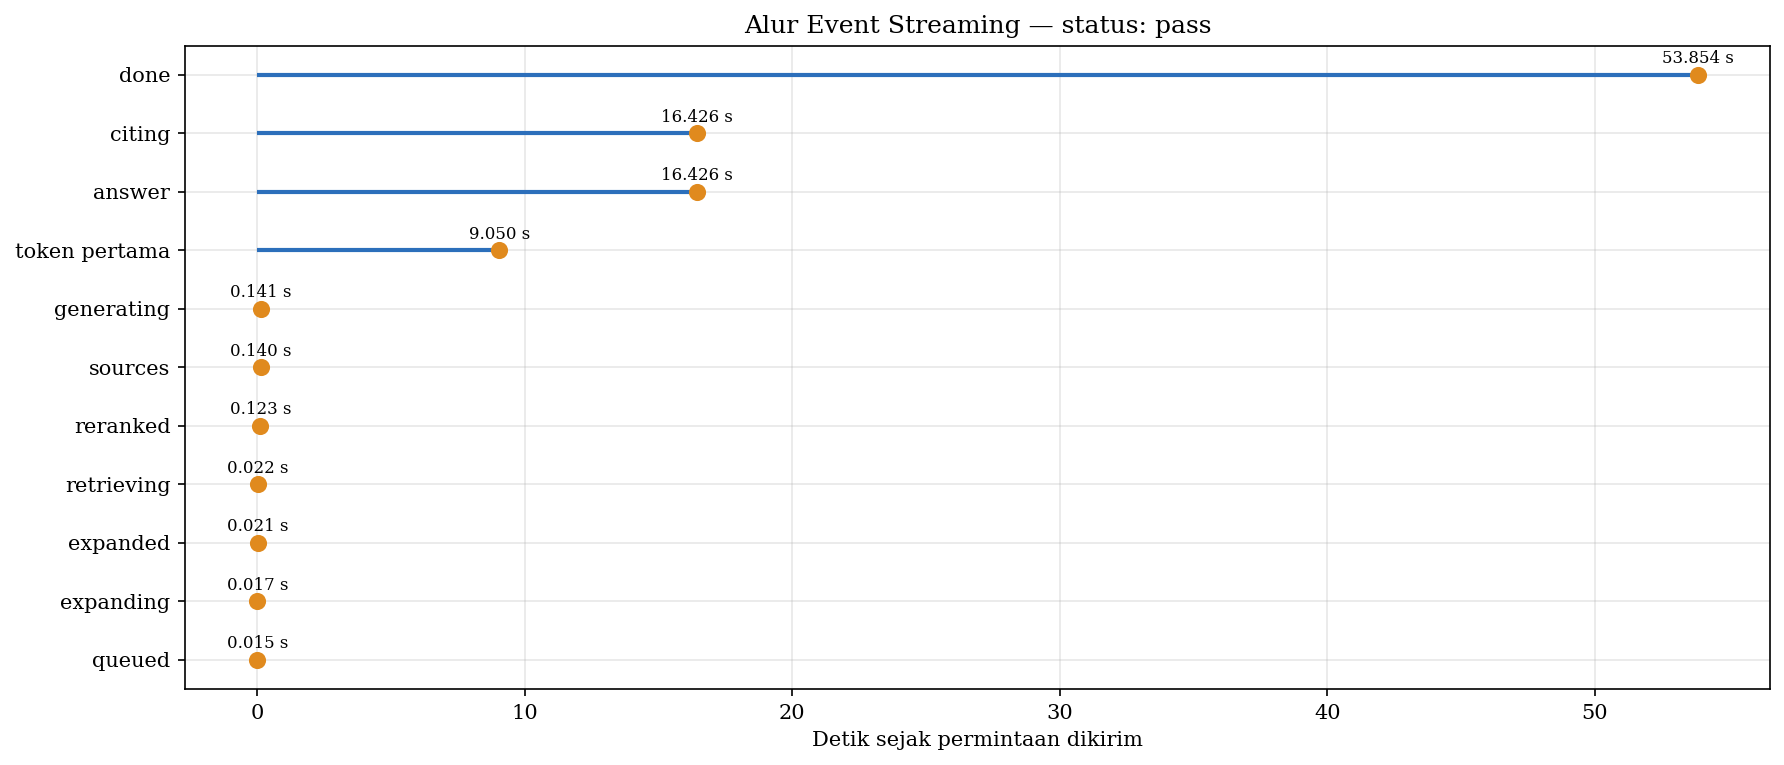

In [28]:
def fig2_timeline_streaming():
    events = pd.DataFrame(stream_result["events"])
    pertama = (events[~events["event"].isin(["heartbeat", "token"])]
               .groupby("event", as_index=False)["elapsed_s"].min()
               .sort_values("elapsed_s"))
    token = events[events["event"] == "token"]["elapsed_s"]
    if len(token):
        pertama = pd.concat([pertama, pd.DataFrame({"event": ["token pertama"],
                                                    "elapsed_s": [token.min()]})], ignore_index=True)
        pertama = pertama.sort_values("elapsed_s")

    fig, ax = plt.subplots(figsize=(12, 5.2))
    y = np.arange(len(pertama))
    ax.hlines(y, 0, pertama["elapsed_s"], color=C_BLUE, lw=2)
    ax.scatter(pertama["elapsed_s"], y, color=C_ORANGE, s=52, zorder=3)
    for yi, v in zip(y, pertama["elapsed_s"]):
        ax.text(v, yi + .2, f"{v:.3f} s", ha="center", fontsize=8)
    ax.set_yticks(y); ax.set_yticklabels(pertama["event"].str.replace("_", " "))
    ax.set_xlabel("Detik sejak permintaan dikirim")
    ax.set_title(f"Alur Event Streaming — status: {stream_result['status']}")
    plt.tight_layout(); plt.savefig("fig02_timeline_streaming.png", bbox_inches="tight"); plt.show()

fig2_timeline_streaming()


## 2. Evaluasi ablasi RAGAS

Bagian ini hanya menampilkan protokol `end_to_end`. Gambar 3 memakai
`ragas_summary.csv`, sedangkan Gambar 4 menghitung empat kontribusi secara berpasangan
per `record_id` dari `ragas_raw.csv` (atau CSV yang sama di dalam `nb20.zip`). Gemma-2
dikeluarkan; Llama dipertahankan sebagai SLM utama dan DeepSeek sebagai benchmark.


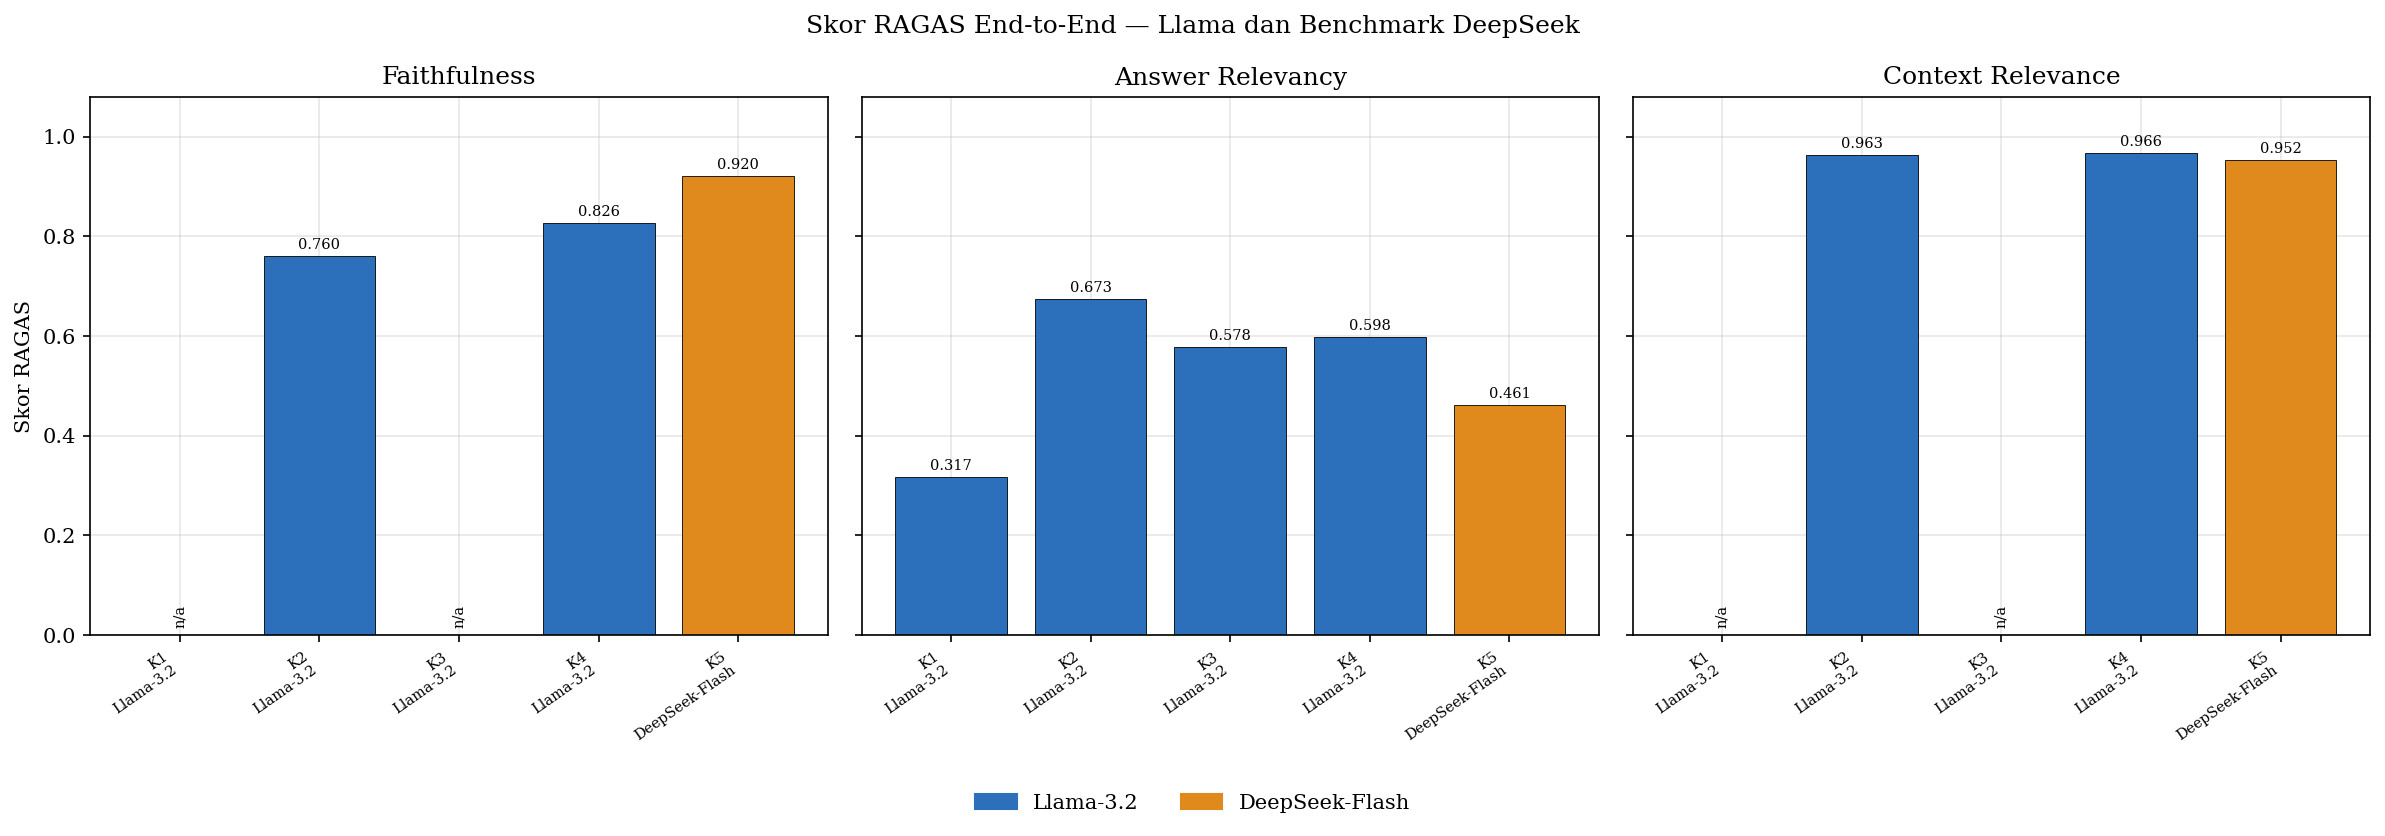

In [29]:
def fig3_ragas_ablasi():
    if ragas_summary is None:
        lewati("fig03: ragas_summary.csv belum tersedia."); return
    d = ragas_summary.copy()
    if "protocol" in d and (d["protocol"] == "end_to_end").any():
        d = d[d["protocol"] == "end_to_end"].copy()
    d["condition_order"] = d["condition"].astype(str).str.extract(r"(\d+)")[0].astype(float)
    d = d.sort_values(["condition_order", "architecture"])
    d["label"] = d["condition"].astype(str) + "\n" + d["architecture"].map(label_model)
    metrik = [("faithfulness", "Faithfulness"),
              ("answer_relevancy", "Answer Relevancy"),
              ("context_relevance", "Context Relevance")]
    fig, axes = plt.subplots(1, len(metrik), figsize=(16, 5.5), sharey=True)
    warna = [warna_model(arsitektur) for arsitektur in d["architecture"]]
    for ax, (kolom, judul) in zip(axes, metrik):
        nilai = d[kolom].to_numpy(float)
        ax.bar(np.arange(len(d)), np.nan_to_num(nilai), color=warna, edgecolor="black", linewidth=.4)
        for x, v in enumerate(nilai):
            ax.text(x, .02 if np.isnan(v) else v + .015,
                    "n/a" if np.isnan(v) else f"{v:.3f}", ha="center", fontsize=7, rotation=90 if np.isnan(v) else 0)
        ax.set_xticks(np.arange(len(d))); ax.set_xticklabels(d["label"], rotation=35, ha="right", fontsize=7)
        ax.set_ylim(0, 1.08); ax.set_title(judul)
    axes[0].set_ylabel("Skor RAGAS")
    fig.legend(
        handles=[Patch(color=C_BLUE, label="Llama-3.2"),
                 Patch(color=C_ORANGE, label="DeepSeek-Flash")],
        loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(.5, -.01),
    )
    fig.suptitle("Skor RAGAS End-to-End — Llama dan Benchmark DeepSeek")
    plt.tight_layout(rect=[0, .07, 1, 1]); plt.savefig("fig03_ragas_ablasi.png", bbox_inches="tight"); plt.show()

fig3_ragas_ablasi()


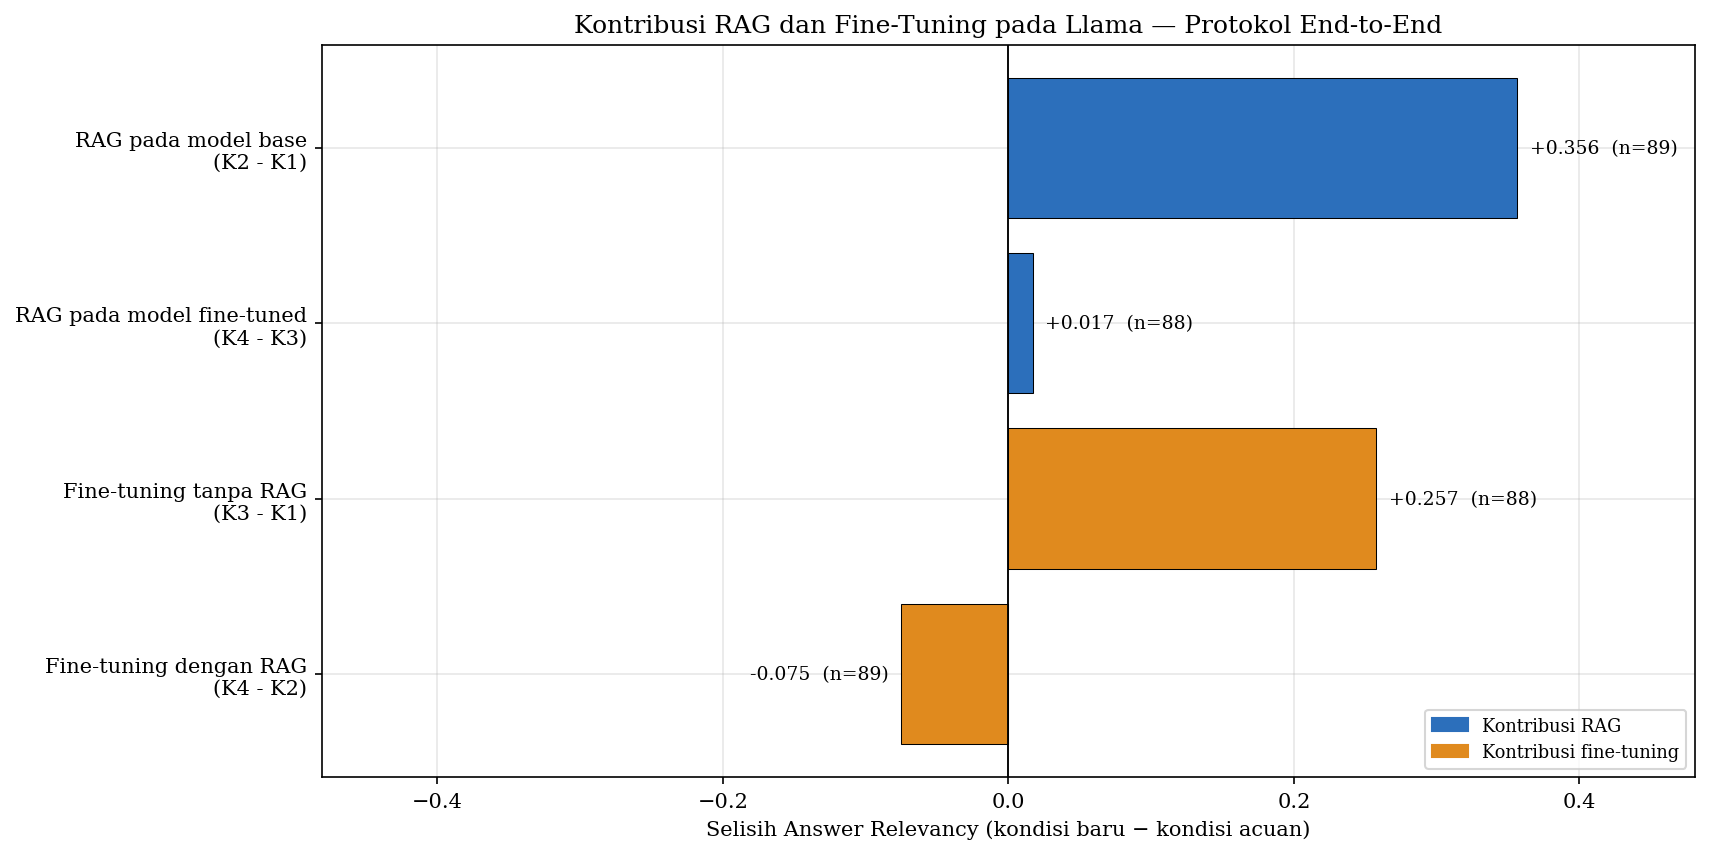

               kontribusi perbandingan  intervensi  delta_answer_relevancy  n_pasangan
      RAG pada model base      K2 - K1         RAG                0.356294          89
RAG pada model fine-tuned      K4 - K3         RAG                0.017125          88
    Fine-tuning tanpa RAG      K3 - K1 Fine-tuning                0.257410          88
   Fine-tuning dengan RAG      K4 - K2 Fine-tuning               -0.074963          89


In [30]:
def fig4_delta_ragas():
    if ragas_raw is None:
        lewati("fig04: ragas_raw.csv atau nb20.zip belum tersedia."); return None

    def delta_berpasangan(kondisi_baru, kondisi_acuan):
        kolom = ["record_id", "answer_relevancy"]
        baru = (ragas_raw[ragas_raw["condition"] == kondisi_baru][kolom]
                .rename(columns={"answer_relevancy": "baru"}))
        acuan = (ragas_raw[ragas_raw["condition"] == kondisi_acuan][kolom]
                 .rename(columns={"answer_relevancy": "acuan"}))
        pasangan = baru.merge(acuan, on="record_id", validate="one_to_one").dropna()
        if pasangan.empty:
            raise ValueError(f"Tidak ada pasangan valid untuk {kondisi_baru}-{kondisi_acuan}")
        return (pasangan["baru"] - pasangan["acuan"]).mean(), len(pasangan)

    spesifikasi = [
        ("RAG pada model base", "K2", "K1", "RAG"),
        ("RAG pada model fine-tuned", "K4", "K3", "RAG"),
        ("Fine-tuning tanpa RAG", "K3", "K1", "Fine-tuning"),
        ("Fine-tuning dengan RAG", "K4", "K2", "Fine-tuning"),
    ]
    baris = []
    for label, kondisi_baru, kondisi_acuan, intervensi in spesifikasi:
        delta, n = delta_berpasangan(kondisi_baru, kondisi_acuan)
        baris.append({
            "kontribusi": label,
            "perbandingan": f"{kondisi_baru} - {kondisi_acuan}",
            "intervensi": intervensi,
            "delta_answer_relevancy": delta,
            "n_pasangan": n,
        })
    hasil = pd.DataFrame(baris)

    fig, ax = plt.subplots(figsize=(11.5, 5.8))
    y = np.arange(len(hasil))
    nilai = hasil["delta_answer_relevancy"].to_numpy(float)
    warna = [C_BLUE if jenis == "RAG" else C_ORANGE for jenis in hasil["intervensi"]]
    ax.barh(y, nilai, color=warna, edgecolor="black", linewidth=.5)
    ax.axvline(0, color="black", lw=.9)
    batas = max(abs(nilai).max(), .01)
    offset = batas * .025
    for yi, (v, n) in enumerate(zip(nilai, hasil["n_pasangan"])):
        ax.text(v + (offset if v >= 0 else -offset), yi, f"{v:+.3f}  (n={n})",
                va="center", ha="left" if v >= 0 else "right", fontsize=9)
    ax.set_yticks(y)
    ax.set_yticklabels([
        f"{label}\n({perbandingan})"
        for label, perbandingan in zip(hasil["kontribusi"], hasil["perbandingan"])
    ])
    ax.invert_yaxis()
    ax.set_xlim(-batas * 1.35, batas * 1.35)
    ax.set_xlabel("Selisih Answer Relevancy (kondisi baru − kondisi acuan)")
    ax.set_title("Kontribusi RAG dan Fine-Tuning pada Llama — Protokol End-to-End")
    ax.legend(handles=[Patch(color=C_BLUE, label="Kontribusi RAG"),
                       Patch(color=C_ORANGE, label="Kontribusi fine-tuning")],
              loc="lower right", fontsize=8.5)
    plt.tight_layout(); plt.savefig("fig04_delta_ragas.png", bbox_inches="tight"); plt.show()

    print(hasil.to_string(index=False))
    return hasil

hasil_kontribusi_ragas = fig4_delta_ragas()


## 3. Evaluasi skenario dan robustness

Grafik memakai hasil Llama-3.2 fine-tuned dan DeepSeek-Flash; seluruh baris Gemma-2
dikeluarkan. Evaluasi skenario menjalankan pipeline RAG secara end-to-end.


/tmp/ipykernel_2412/188874823.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.savefig("fig05_ragas_per_skenario.png", bbox_inches="tight"); plt.show()


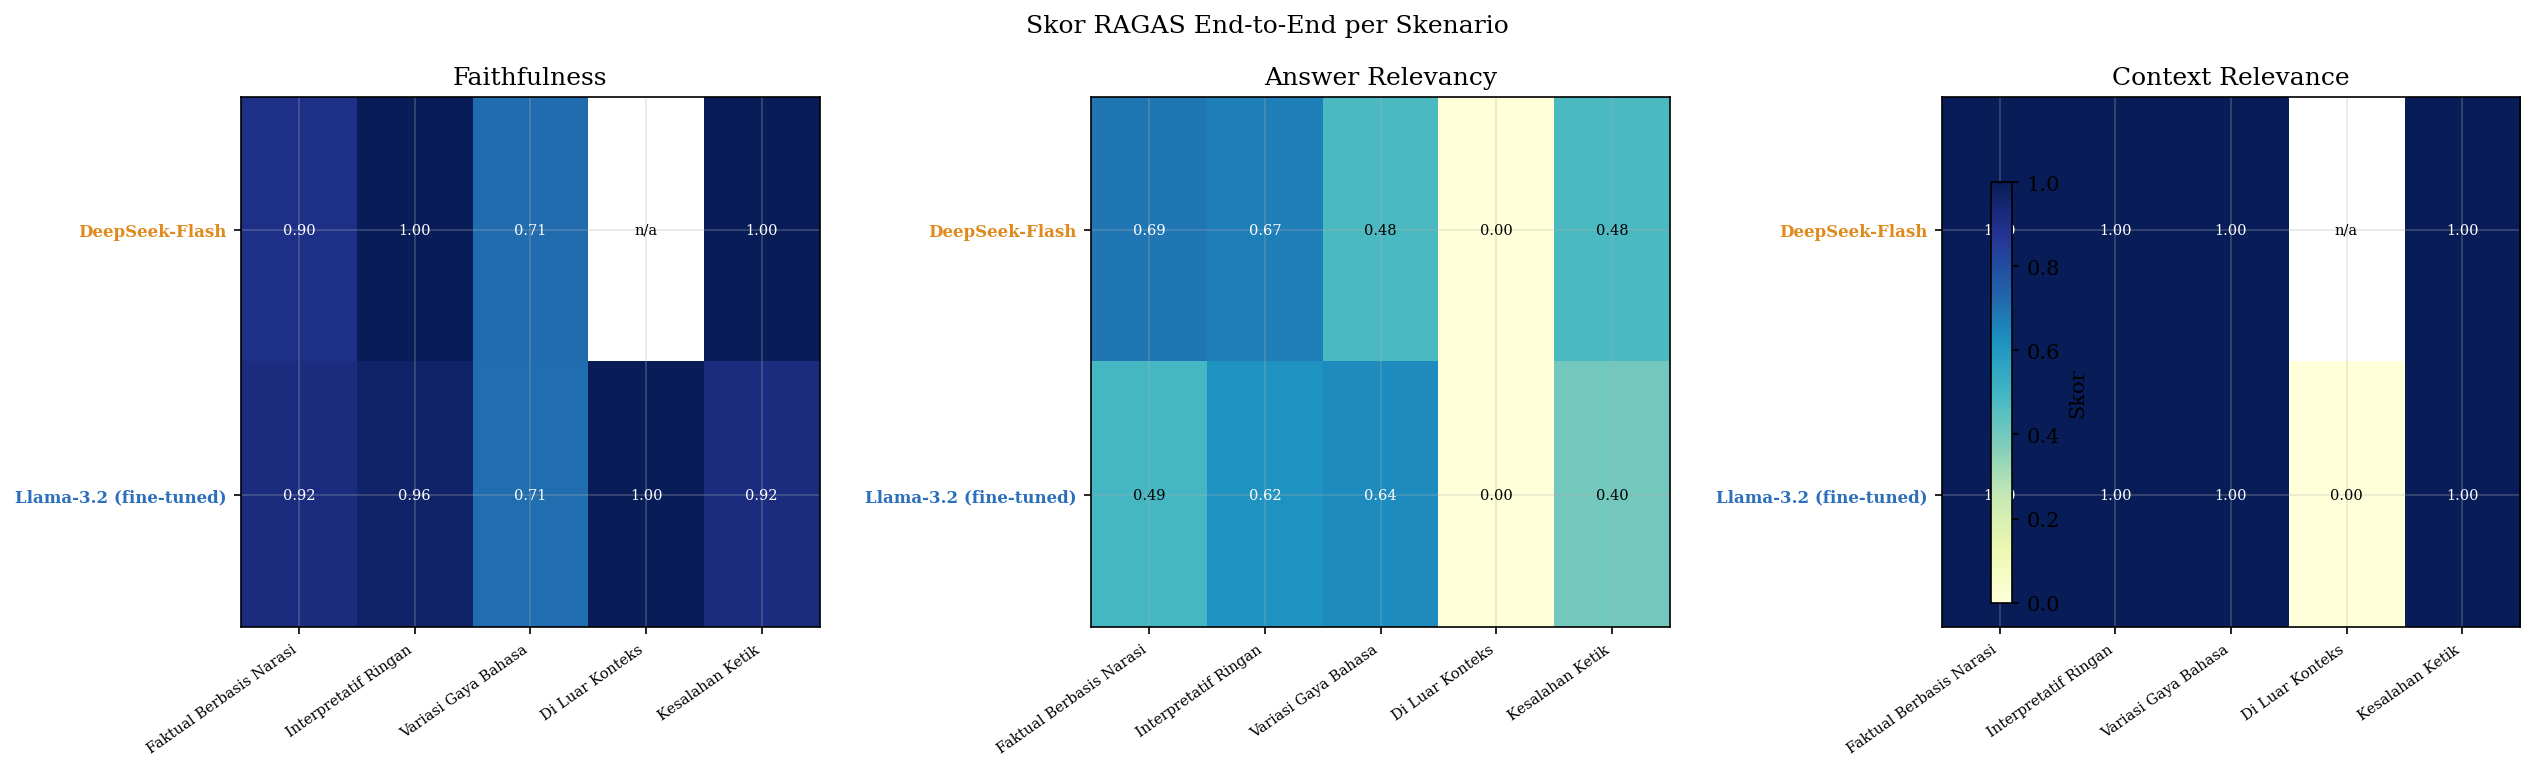

In [31]:
def fig5_ragas_per_skenario():
    d = scenario_by_scenario.copy()
    model_order = sorted(d["model_key"].dropna().unique(), key=str)
    scenario_order = sorted(d["scenario"].dropna().unique(),
                            key=lambda x: int(re.match(r"(\d+)", str(x)).group(1)) if re.match(r"(\d+)", str(x)) else 999)
    metrik = [("faithfulness_mean", "Faithfulness"),
              ("answer_relevancy_mean", "Answer Relevancy"),
              ("context_relevance_mean", "Context Relevance")]
    fig, axes = plt.subplots(1, len(metrik), figsize=(17, 5.2))
    for ax, (kolom, judul) in zip(axes, metrik):
        mat = d.pivot(index="model_key", columns="scenario", values=kolom).reindex(index=model_order, columns=scenario_order)
        im = ax.imshow(mat, cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(len(scenario_order))); ax.set_xticklabels([label_skenario(s) for s in scenario_order], rotation=35, ha="right", fontsize=7)
        ax.set_yticks(range(len(model_order))); ax.set_yticklabels([label_model(m) for m in model_order], fontsize=8)
        for tick, model in zip(ax.get_yticklabels(), model_order):
            tick.set_color(warna_model(model)); tick.set_fontweight("bold")
        for i in range(len(model_order)):
            for j in range(len(scenario_order)):
                v = mat.iloc[i, j]
                ax.text(j, i, "n/a" if pd.isna(v) else f"{v:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if pd.notna(v) and v > .58 else "black")
        ax.set_title(judul)
    fig.colorbar(im, ax=axes, shrink=.7, label="Skor")
    fig.suptitle("Skor RAGAS End-to-End per Skenario")
    plt.tight_layout(); plt.savefig("fig05_ragas_per_skenario.png", bbox_inches="tight"); plt.show()

fig5_ragas_per_skenario()


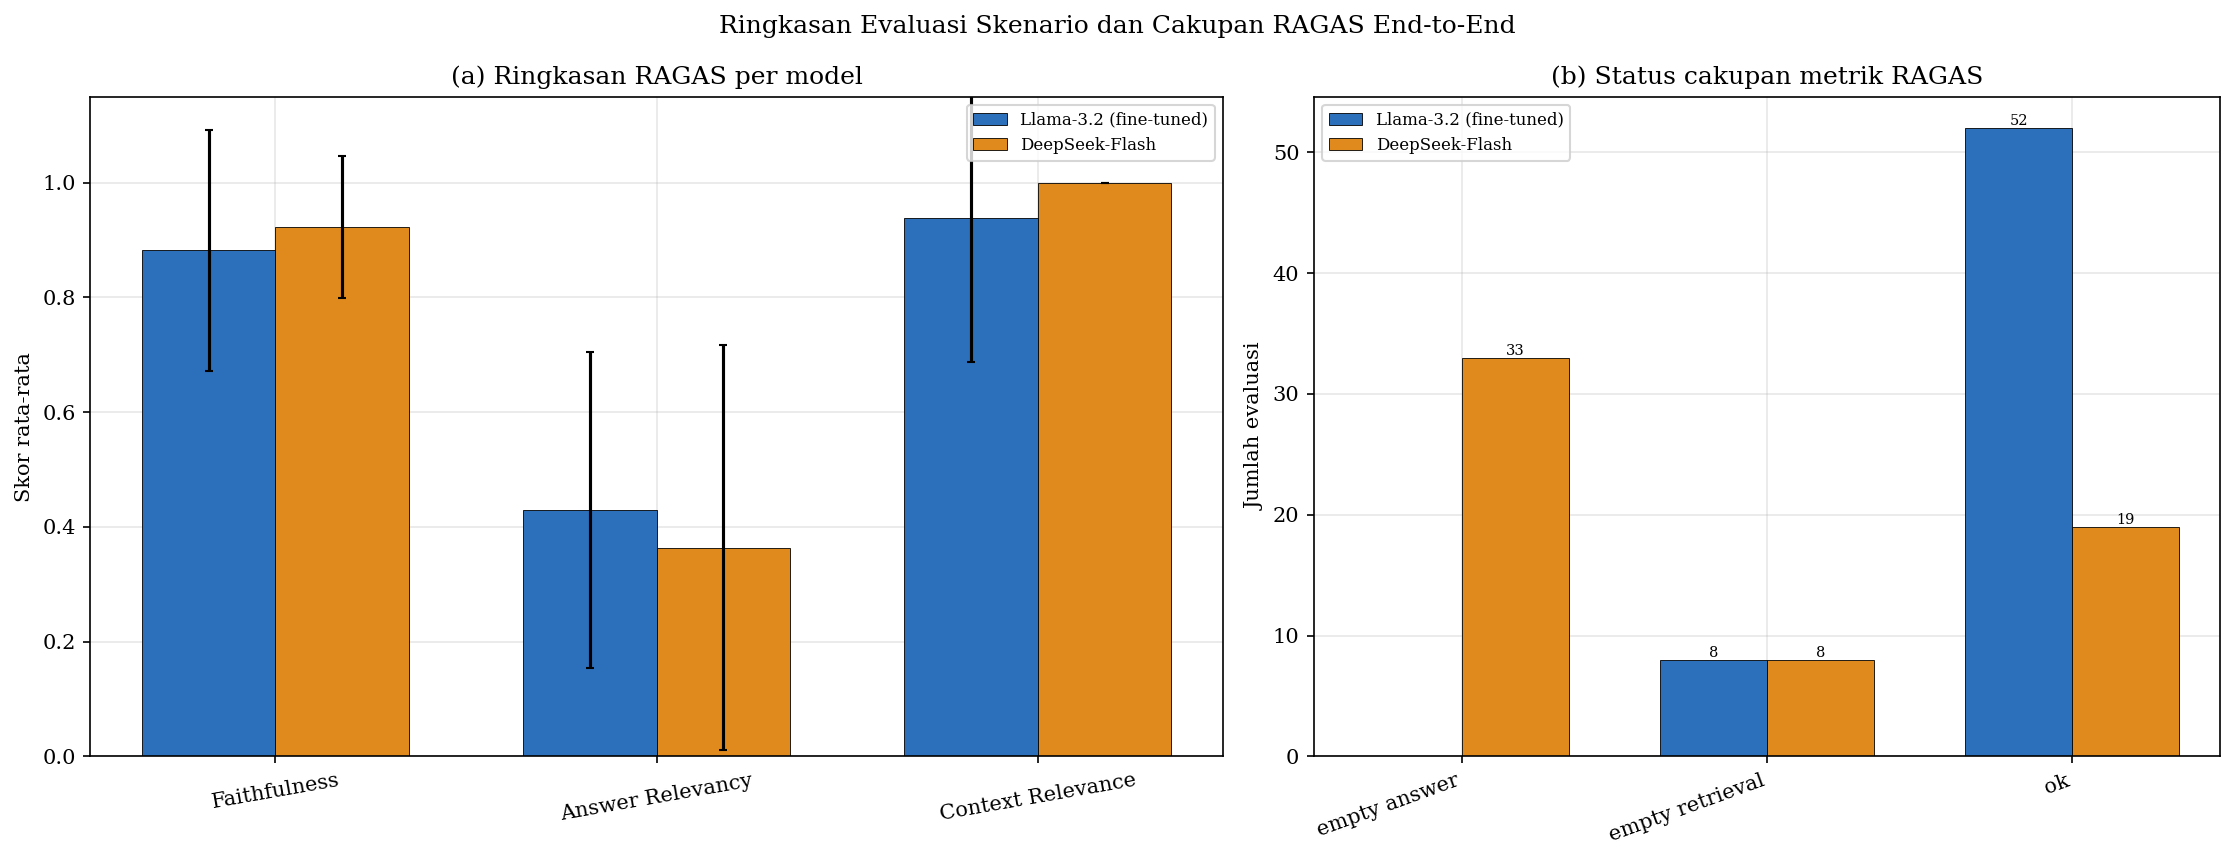

In [32]:
def fig6_ringkasan_model_dan_coverage():
    d = scenario_by_model.copy().set_index("model_key")
    model_order = [m for m in MODEL_SKENARIO if m in d.index]
    metrik = [("faithfulness_mean", "Faithfulness"),
              ("answer_relevancy_mean", "Answer Relevancy"),
              ("context_relevance_mean", "Context Relevance")]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.25, 1]})

    ax = axes[0]
    x = np.arange(len(metrik)); w = .7 / max(len(model_order), 1)
    for i, model in enumerate(model_order):
        nilai = np.array([d.loc[model, kolom] for kolom, _ in metrik], dtype=float)
        galat = np.array([
            d.loc[model, kolom.replace("_mean", "_std")]
            if kolom.replace("_mean", "_std") in d.columns else 0
            for kolom, _ in metrik
        ], dtype=float)
        galat = np.nan_to_num(galat)
        posisi = x + (i - (len(model_order) - 1) / 2) * w
        ax.bar(posisi, nilai, w, yerr=galat, capsize=2,
               color=warna_model(model), edgecolor="black", linewidth=.4,
               label=label_model(model))
    ax.set_xticks(x); ax.set_xticklabels([label for _, label in metrik], rotation=10)
    ax.set_ylim(0, 1.15); ax.set_ylabel("Skor rata-rata")
    ax.set_title("(a) Ringkasan RAGAS per model"); ax.legend(fontsize=8)

    ax = axes[1]
    cov = (scenario_coverage.groupby(["model_key", "status"])["n"].sum()
           .unstack(fill_value=0).reindex(model_order, fill_value=0))
    status_order = list(cov.columns)
    x = np.arange(len(status_order)); w = .7 / max(len(model_order), 1)
    for i, model in enumerate(model_order):
        posisi = x + (i - (len(model_order) - 1) / 2) * w
        nilai = cov.loc[model, status_order].to_numpy(float)
        ax.bar(posisi, nilai, w, color=warna_model(model), edgecolor="black",
               linewidth=.4, label=label_model(model))
        for xi, v in zip(posisi, nilai):
            if v > 0:
                ax.text(xi, v, f"{v:.0f}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels([s.replace("_", " ") for s in status_order],
                                         rotation=20, ha="right")
    ax.set_ylabel("Jumlah evaluasi"); ax.set_title("(b) Status cakupan metrik RAGAS")
    ax.legend(fontsize=8)
    fig.suptitle("Ringkasan Evaluasi Skenario dan Cakupan RAGAS End-to-End")
    plt.tight_layout(); plt.savefig("fig06_ringkasan_model_coverage.png", bbox_inches="tight"); plt.show()

fig6_ringkasan_model_dan_coverage()


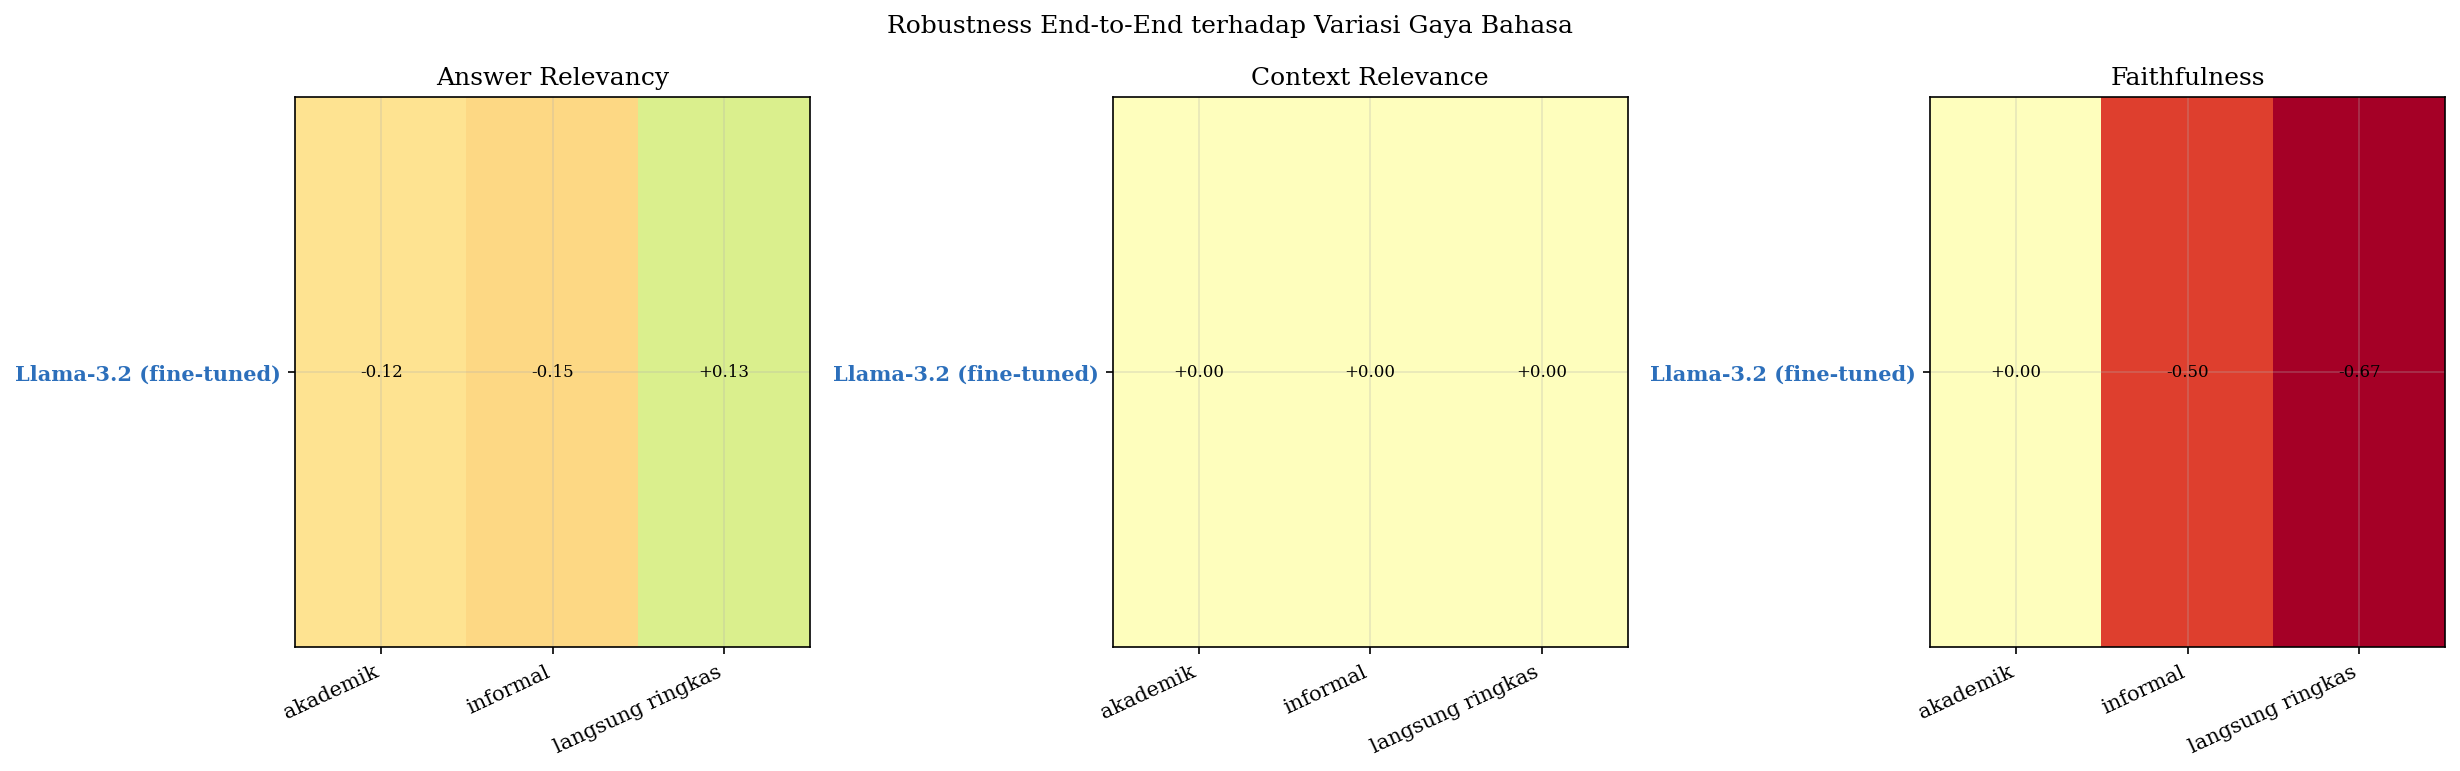

In [33]:
def fig7_robustness_gaya():
    delta_cols = ["delta_faithfulness_vs_formal", "delta_answer_relevancy_vs_formal", "delta_context_relevance_vs_formal"]
    d = style_comparison[style_comparison["variant"] != "formal"].copy()
    panjang = d.melt(id_vars=["model_key", "style"], value_vars=delta_cols,
                     var_name="metric", value_name="delta").dropna(subset=["delta"])
    if panjang.empty:
        lewati("fig07: delta variasi gaya tidak tersedia."); return
    g = panjang.groupby(["model_key", "style", "metric"], as_index=False)["delta"].mean()
    metrics = list(dict.fromkeys(g["metric"]))
    fig, axes = plt.subplots(1, len(metrics), figsize=(5.5 * len(metrics), 5.2), squeeze=False)
    for ax, metric in zip(axes[0], metrics):
        sub = g[g["metric"] == metric]
        pivot = sub.pivot(index="model_key", columns="style", values="delta")
        im = ax.imshow(pivot, cmap="RdYlGn", vmin=-max(abs(panjang["delta"]).max(), .01),
                       vmax=max(abs(panjang["delta"]).max(), .01), aspect="auto")
        ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels([str(x).replace("_", " ") for x in pivot.columns], rotation=25, ha="right")
        ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels([label_model(m) for m in pivot.index])
        for tick, model in zip(ax.get_yticklabels(), pivot.index):
            tick.set_color(warna_model(model)); tick.set_fontweight("bold")
        for i in range(len(pivot.index)):
            for j in range(len(pivot.columns)):
                v = pivot.iloc[i, j]
                ax.text(j, i, "n/a" if pd.isna(v) else f"{v:+.2f}", ha="center", va="center", fontsize=8)
        ax.set_title(metric.replace("delta_", "").replace("_vs_formal", "").replace("_", " ").title())
    fig.suptitle("Robustness End-to-End terhadap Variasi Gaya Bahasa")
    plt.tight_layout(); plt.savefig("fig07_robustness_gaya.png", bbox_inches="tight"); plt.show()

fig7_robustness_gaya()


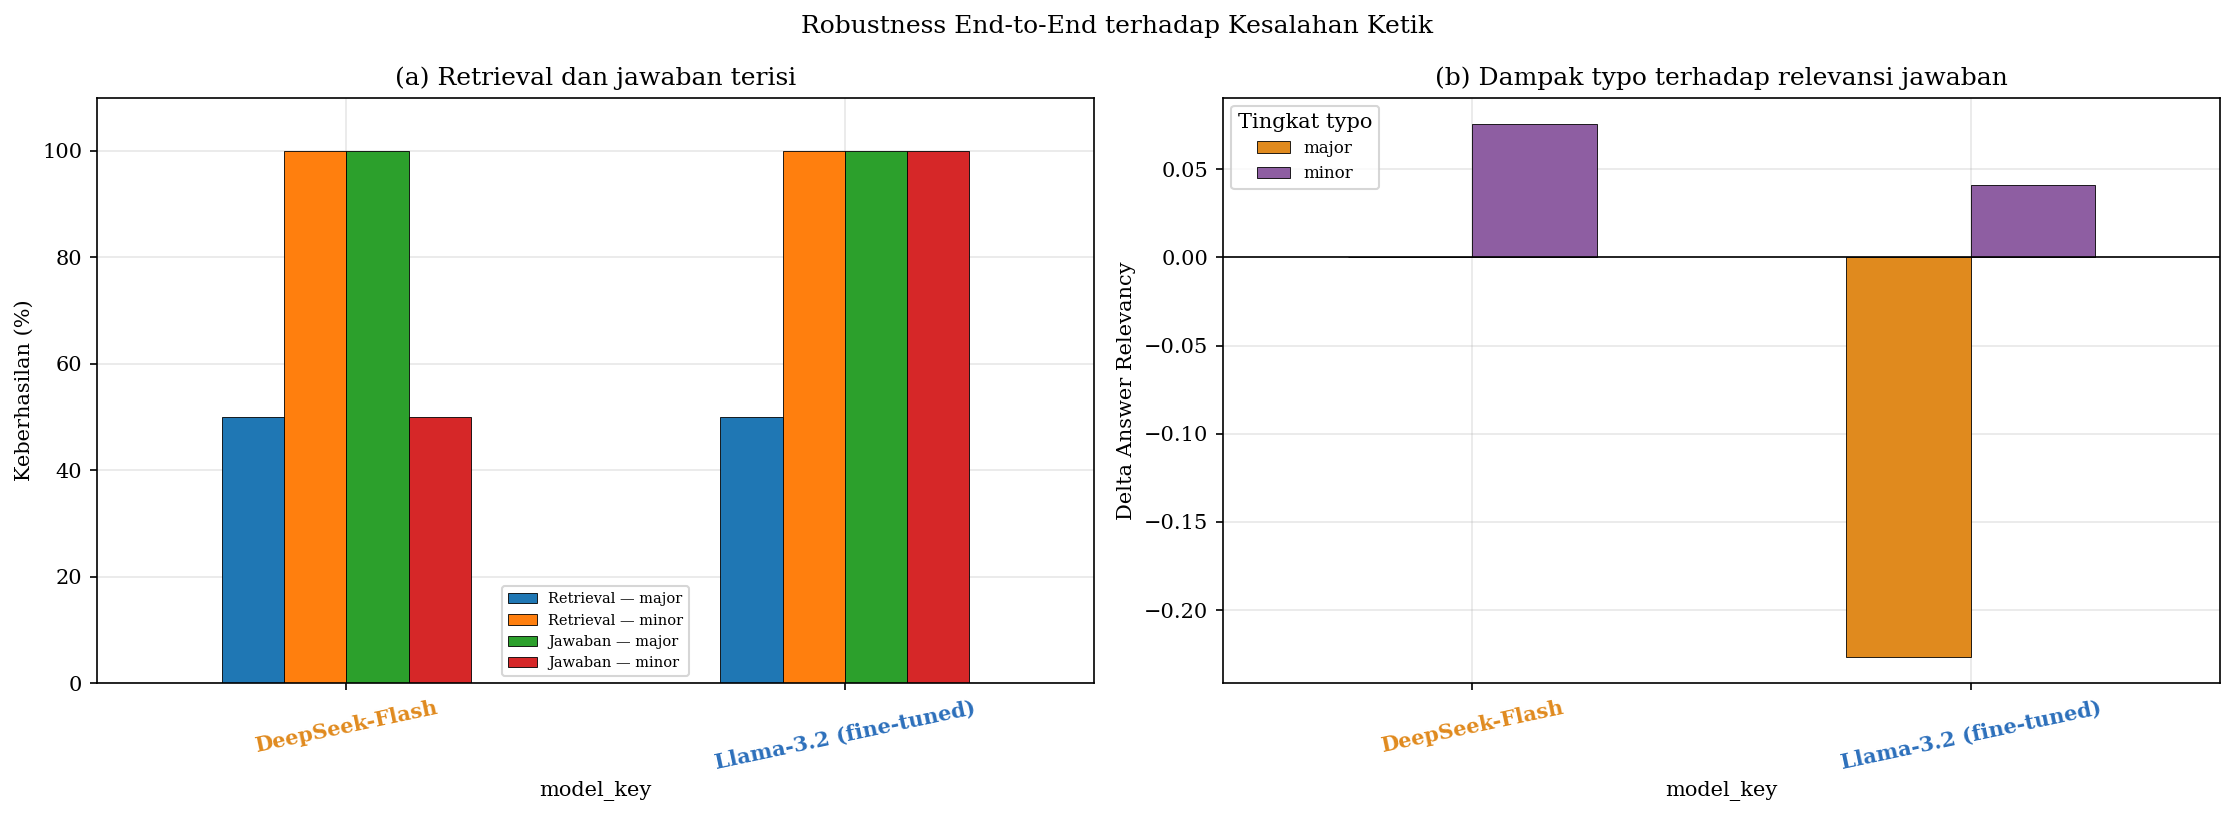

In [34]:
def _terisi(series):
    return series.notna() & ~series.astype(str).str.strip().isin(["", "[]", "{}", "nan", "None"])

def fig8_robustness_typo():
    typo_rows = scenario_results[scenario_results["typo_severity"].notna()].copy()
    if typo_rows.empty:
        lewati("fig08: record typo tidak tersedia."); return
    typo_rows["retrieval_ok"] = _terisi(typo_rows["retrieved_context"])
    typo_rows["answer_ok"] = _terisi(typo_rows["answer"])
    keberhasilan = typo_rows.groupby(["model_key", "typo_severity"])[["retrieval_ok", "answer_ok"]].mean().mul(100)

    delta = (typo_comparison.groupby(["model_key", "typo_severity"])
             [["delta_faithfulness_vs_clean", "delta_answer_relevancy_vs_clean"]].mean())
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    ax = axes[0]
    plot = keberhasilan.unstack("typo_severity")
    plot.columns = [f"{'Retrieval' if metrik == 'retrieval_ok' else 'Jawaban'} — {tingkat}"
                    for metrik, tingkat in plot.columns]
    plot.plot(kind="bar", ax=ax, edgecolor="black", linewidth=.4)
    ax.set_xticklabels([label_model(m) for m in plot.index], rotation=12)
    for tick, model in zip(ax.get_xticklabels(), plot.index):
        tick.set_color(warna_model(model)); tick.set_fontweight("bold")
    ax.set_ylabel("Keberhasilan (%)"); ax.set_ylim(0, 110)
    ax.set_title("(a) Retrieval dan jawaban terisi"); ax.legend(fontsize=7, title=None)

    ax = axes[1]
    d = delta["delta_answer_relevancy_vs_clean"].unstack("typo_severity")
    d.plot(kind="bar", ax=ax, color=[C_ORANGE, C_PURPLE][:len(d.columns)], edgecolor="black", linewidth=.4)
    ax.axhline(0, color="black", lw=.8); ax.set_xticklabels([label_model(m) for m in d.index], rotation=12)
    for tick, model in zip(ax.get_xticklabels(), d.index):
        tick.set_color(warna_model(model)); tick.set_fontweight("bold")
    ax.set_ylabel("Delta Answer Relevancy"); ax.set_title("(b) Dampak typo terhadap relevansi jawaban")
    ax.legend(fontsize=8, title="Tingkat typo")
    fig.suptitle("Robustness End-to-End terhadap Kesalahan Ketik")
    plt.tight_layout(); plt.savefig("fig08_robustness_typo.png", bbox_inches="tight"); plt.show()

fig8_robustness_typo()


## 4. Retrieval, performa, dan kapasitas sistem versi akhir

Bagian ini memakai run terbaru yang lengkap pada `Hasil/tujuan3/versi-final`, yaitu
keluaran notebook 23b dan hanya menampilkan Llama-3.2 fine-tuned. Cakupannya empat
pertanyaan dengan tiga ulangan, sehingga terdapat 12 permintaan terukur. Ringkasan adalah
campuran kondisi cache sesuai eksekusi; grafik cache memisahkannya kembali.

`retrieval_s` sudah merupakan jumlah perluasan kueri dan pencarian/reranking.
`client_total_s` dipakai sebagai waktu respons pengguna, sedangkan `first_token_s`
adalah waktu token pertama di backend. `citation_s=0` menunjukkan generasi ringkasan
sumber telah dihapus pada versi akhir. Status HTTP `ok` tidak dianggap bukti jawaban benar.

Profil kapasitas tambahan menguji concurrency klien 1, 2, dan 4. Pertanyaan pada profil
tersebut dipanaskan dan diulang, sehingga hasilnya menggambarkan beban terukur dengan
kebijakan cache yang tercatat, bukan SLA produksi atau trafik pertanyaan baru.


/tmp/ipykernel_2412/3675775995.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxes = ax.boxplot(data, labels=[label_model(m) for m in model_order],


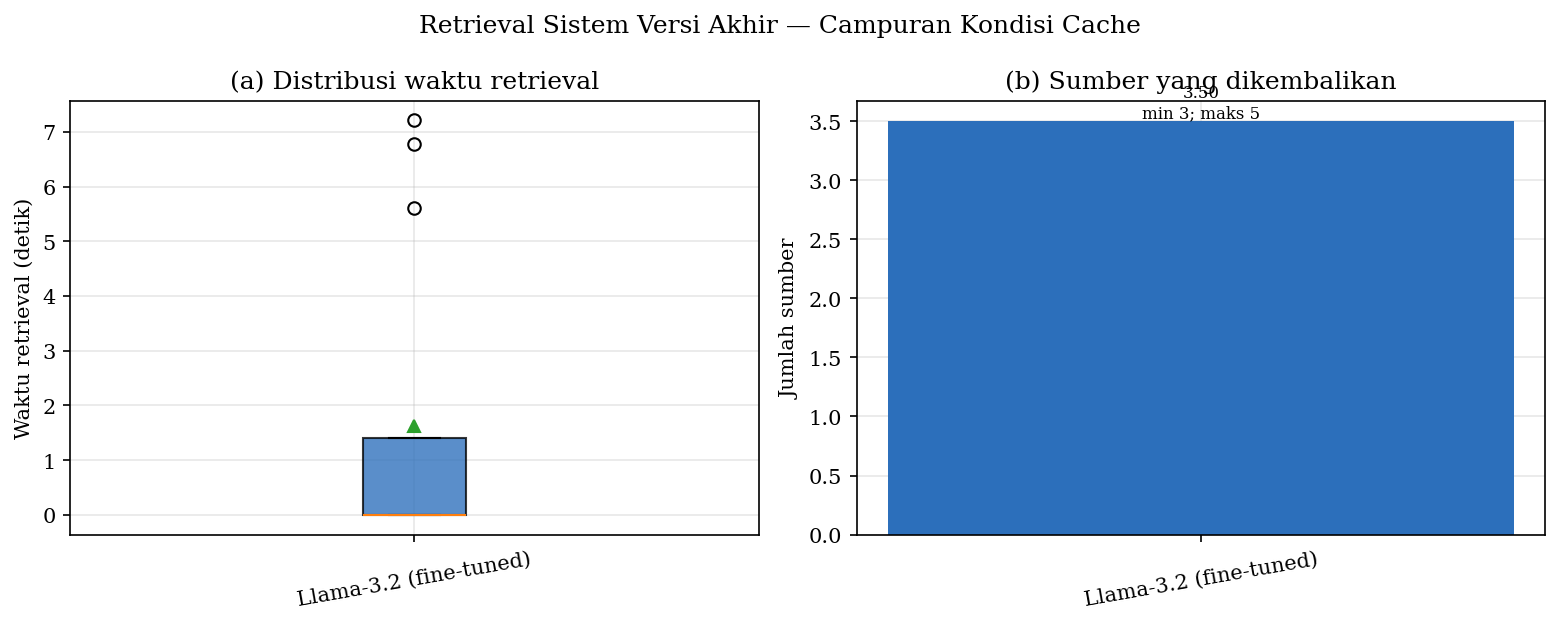

In [35]:
def _e2e():
    d = performance[performance["test_scope"].astype(str).eq("e2e_system_final")].copy()
    return d[d["status"].astype(str).str.lower().eq("ok")] if "status" in d else d

def _urutan_model(data):
    utama = [MODEL_UTAMA]
    tersedia = list(data["model_key"].dropna().astype(str).unique())
    return [m for m in utama if m in tersedia] + sorted(set(tersedia) - set(utama))

def _kondisi_cache(data):
    exp = data["cache_expansion"].astype(str).str.lower().eq("true")
    cari = data["cache_search_rerank"].astype(str).str.lower().eq("true")
    return np.select(
        [~exp & ~cari, ~exp & cari, exp & ~cari, exp & cari],
        ["Miss kedua cache", "Miss ekspansi; hit pencarian",
         "Hit ekspansi; miss pencarian", "Hit kedua cache"],
        default="Kondisi lain",
    )

def fig9_retrieval():
    d = _e2e()
    if d.empty:
        lewati("fig09: pengukuran versi akhir tidak tersedia."); return
    model_order = _urutan_model(d)
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

    ax = axes[0]
    data = [d.loc[d["model_key"] == m, "retrieval_s"].dropna() for m in model_order]
    boxes = ax.boxplot(data, labels=[label_model(m) for m in model_order],
                       showmeans=True, patch_artist=True)
    for patch, model in zip(boxes["boxes"], model_order):
        patch.set_facecolor(warna_model(model)); patch.set_alpha(.78)
    ax.set_ylabel("Waktu retrieval (detik)")
    ax.set_title("(a) Distribusi waktu retrieval")
    ax.tick_params(axis="x", labelrotation=10)

    ax = axes[1]
    sumber = d.groupby("model_key")["source_count"].agg(["mean", "min", "max"]).reindex(model_order)
    bars = ax.bar([label_model(m) for m in model_order], sumber["mean"],
                  color=[warna_model(m) for m in model_order], width=.58)
    for bar, (_, row) in zip(bars, sumber.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, row["mean"],
                f"{row['mean']:.2f}\nmin {row['min']:.0f}; maks {row['max']:.0f}",
                ha="center", va="bottom", fontsize=8)
    ax.set_ylabel("Jumlah sumber")
    ax.set_title("(b) Sumber yang dikembalikan")
    ax.tick_params(axis="x", labelrotation=10)
    fig.suptitle("Retrieval Sistem Versi Akhir — Campuran Kondisi Cache")
    plt.tight_layout(); plt.savefig("fig09_retrieval.png", bbox_inches="tight"); plt.show()

fig9_retrieval()


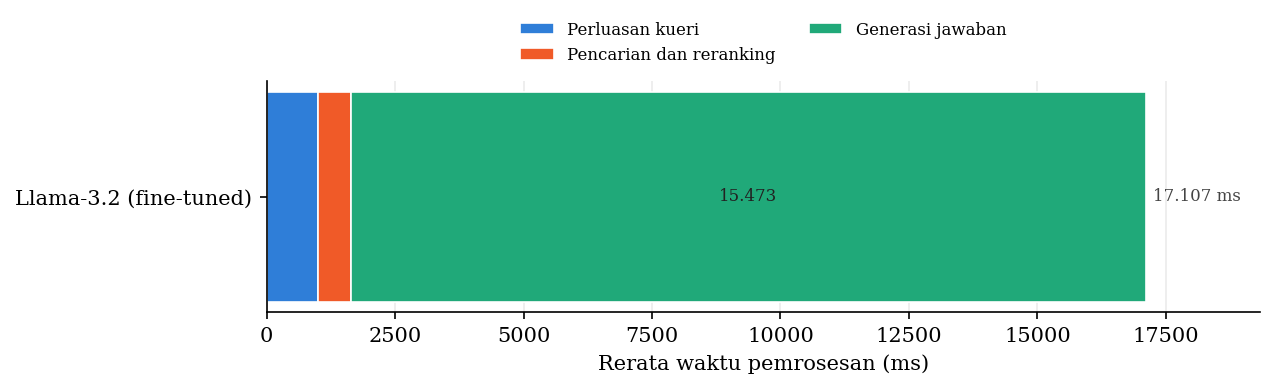

In [46]:
def fig10_komposisi_waktu():
    d = _e2e()
    tahap_info = [
        ("expansion_s", "Perluasan kueri", "#2f7ed8"),
        ("search_rerank_s", "Pencarian dan reranking", "#f05a28"),
        ("generation_s", "Generasi jawaban", "#20a979"),

    ]
    tahap_info = [(kolom, label, warna) for kolom, label, warna in tahap_info
                  if kolom in d and d[kolom].notna().any()]
    if d.empty or not tahap_info:
        lewati("fig10: komponen waktu versi akhir tidak tersedia."); return

    tahap = [kolom for kolom, _, _ in tahap_info]
    model_order = _urutan_model(d)
    rata_ms = d.groupby("model_key")[tahap].mean().reindex(model_order).mul(1000)
    total_ms = rata_ms.sum(axis=1).to_numpy(float)
    y = np.arange(len(rata_ms))

    fig, ax = plt.subplots(figsize=(8.6, max(2.7, .68 * len(rata_ms) + 1.7)))
    left = np.zeros(len(rata_ms))
    for kolom, label, warna in tahap_info:
        nilai = rata_ms[kolom].to_numpy(float)
        ax.barh(y, nilai, left=left, height=.42, label=label,
                color=warna, edgecolor="white", linewidth=.8)
        for yi, (awal, v, total) in enumerate(zip(left, nilai, total_ms)):
            if v > 0 and total > 0 and v / total >= .08:
                ax.text(awal + v/2, yi, f"{v:,.0f}".replace(",", "."),
                        ha="center", va="center", fontsize=8, color="#222222")
        left += nilai

    ruang = max(total_ms.max() * .13, 1)
    for yi, total in enumerate(total_ms):
        ax.text(total + ruang * .06, yi, f"{total:,.0f} ms".replace(",", "."),
                ha="left", va="center", fontsize=8, color="#444444")
    ax.set_yticks(y); ax.set_yticklabels([label_model(m) for m in model_order])
    ax.invert_yaxis(); ax.set_xlim(0, total_ms.max() + ruang)
    ax.set_xlabel("Rerata waktu pemrosesan (ms)")
    ax.grid(axis="y", visible=False); ax.grid(axis="x", alpha=.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, ncol=2, loc="lower center", bbox_to_anchor=(.5, 1.01), frameon=False)
    plt.tight_layout(); plt.savefig("fig10_komposisi_waktu.png", bbox_inches="tight"); plt.show()

fig10_komposisi_waktu()


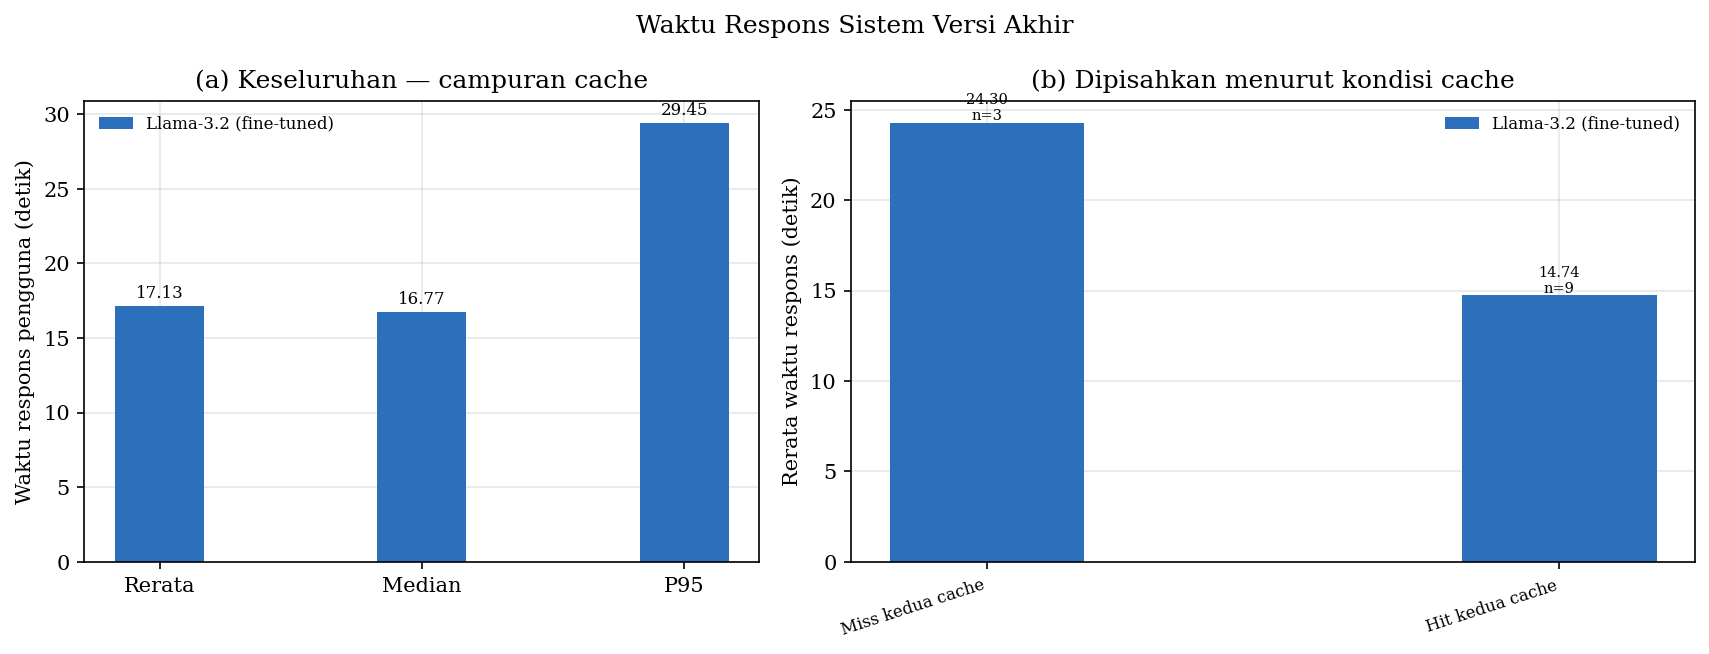

In [37]:
def fig11_ringkasan_performa():
    d = _e2e()
    if d.empty:
        lewati("fig11: pengukuran versi akhir tidak tersedia."); return
    model_order = _urutan_model(d)
    warna = [warna_model(m) for m in model_order]
    ringkas = d.groupby("model_key")["client_total_s"].agg(
        rerata="mean", median="median", p95=lambda s: s.quantile(.95)
    ).reindex(model_order)

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
    ax = axes[0]
    x = np.arange(len(ringkas.columns)); lebar = .34
    for i, model in enumerate(model_order):
        nilai = ringkas.loc[model].to_numpy(float)
        bars = ax.bar(x + (i - (len(model_order)-1)/2)*lebar, nilai, lebar,
                      label=label_model(model), color=warna[i])
        ax.bar_label(bars, labels=[f"{v:.2f}" for v in nilai], padding=2, fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(["Rerata", "Median", "P95"])
    ax.set_ylabel("Waktu respons pengguna (detik)")
    ax.set_title("(a) Keseluruhan — campuran cache")
    ax.legend(fontsize=8, frameon=False)

    dc = d.copy(); dc["kondisi_cache"] = _kondisi_cache(dc)
    urutan_cache = [x for x in ["Miss kedua cache", "Miss ekspansi; hit pencarian",
                                "Hit ekspansi; miss pencarian", "Hit kedua cache"]
                    if x in set(dc["kondisi_cache"])]
    rata = dc.groupby(["kondisi_cache", "model_key"])["client_total_s"].agg(["mean", "size"])
    ax = axes[1]; x = np.arange(len(urutan_cache)); lebar = .34
    for i, model in enumerate(model_order):
        nilai = [rata.loc[(k, model), "mean"] if (k, model) in rata.index else np.nan for k in urutan_cache]
        jumlah = [int(rata.loc[(k, model), "size"]) if (k, model) in rata.index else 0 for k in urutan_cache]
        bars = ax.bar(x + (i - (len(model_order)-1)/2)*lebar, nilai, lebar,
                      label=label_model(model), color=warna[i])
        for bar, v, n in zip(bars, nilai, jumlah):
            if pd.notna(v):
                ax.text(bar.get_x()+bar.get_width()/2, v, f"{v:.2f}\nn={n}",
                        ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(urutan_cache, rotation=18, ha="right", fontsize=8)
    ax.set_ylabel("Rerata waktu respons (detik)")
    ax.set_title("(b) Dipisahkan menurut kondisi cache")
    ax.legend(fontsize=8, frameon=False)
    fig.suptitle("Waktu Respons Sistem Versi Akhir")
    plt.tight_layout(); plt.savefig("fig11_ringkasan_performa.png", bbox_inches="tight"); plt.show()

fig11_ringkasan_performa()


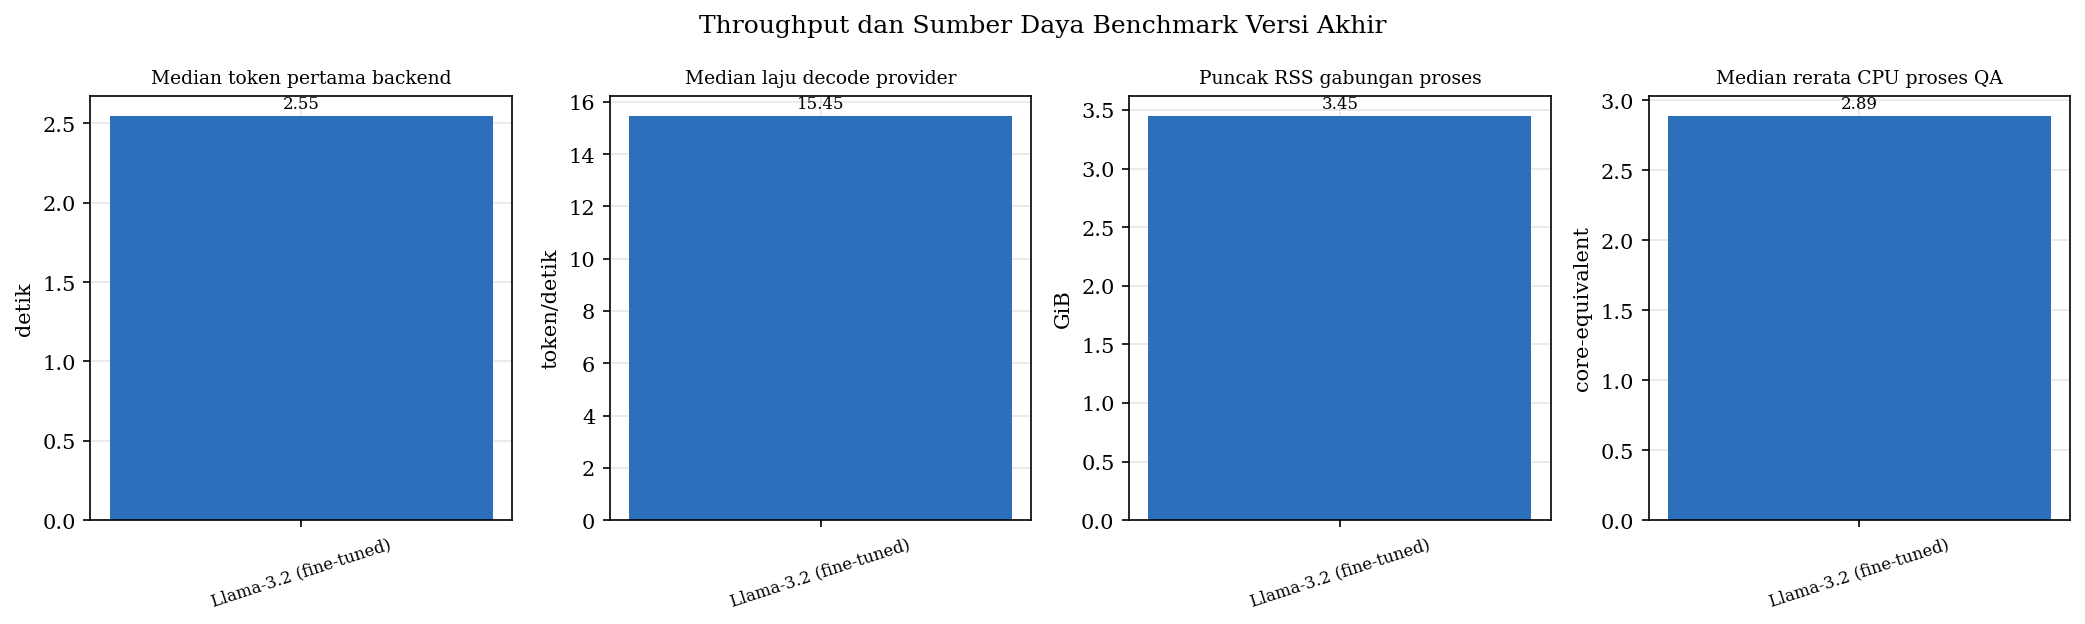

Baris dengan metrik token provider: {'llama3.2-finetuned': 9}
GPU tidak divisualisasikan: peak VRAM per proses/perangkat tidak tersedia.


In [38]:
def fig12_throughput_dan_sumberdaya():
    d = _e2e()
    if d.empty:
        lewati("fig12: pengukuran versi akhir tidak tersedia."); return
    model_order = _urutan_model(d)
    warna = [warna_model(m) for m in model_order]
    token_rows = d[d["provider_metrics_available"].astype(str).str.lower().eq("true")].copy()

    metrik = [
        (d.groupby("model_key")["first_token_s"].median().reindex(model_order),
         "Median token pertama backend", "detik", "{:.2f}"),
        (token_rows.groupby("model_key")["answer_tokens_per_s"].median().reindex(model_order),
         "Median laju decode provider", "token/detik", "{:.2f}"),
        (d.groupby("model_key")["peak_process_rss_mb"].max().reindex(model_order) / 1024,
         "Puncak RSS gabungan proses", "GiB", "{:.2f}"),
        (d.groupby("model_key")["qa_cpu_mean_cores"].median().reindex(model_order),
         "Median rerata CPU proses QA", "core-equivalent", "{:.2f}"),
    ]
    fig, axes = plt.subplots(1, 4, figsize=(14, 4.2))
    for ax, (nilai, judul, unit, fmt) in zip(axes, metrik):
        bars = ax.bar([label_model(m) for m in model_order], nilai.to_numpy(float),
                      color=warna, width=.58)
        labels = ["n/a" if pd.isna(v) else fmt.format(v) for v in nilai]
        ax.bar_label(bars, labels=labels, padding=2, fontsize=8)
        ax.set_ylabel(unit); ax.set_title(judul, fontsize=9)
        ax.tick_params(axis="x", labelrotation=18, labelsize=8)
    fig.suptitle("Throughput dan Sumber Daya Benchmark Versi Akhir")
    plt.tight_layout(); plt.savefig("fig12_throughput_sumberdaya.png", bbox_inches="tight"); plt.show()

    jumlah_token = token_rows.groupby("model_key").size().reindex(model_order, fill_value=0)
    print("Baris dengan metrik token provider:", jumlah_token.to_dict())
    if d["peak_qa_gpu_single_device_mb"].dropna().empty:
        print("GPU tidak divisualisasikan: peak VRAM per proses/perangkat tidak tersedia.")

fig12_throughput_dan_sumberdaya()


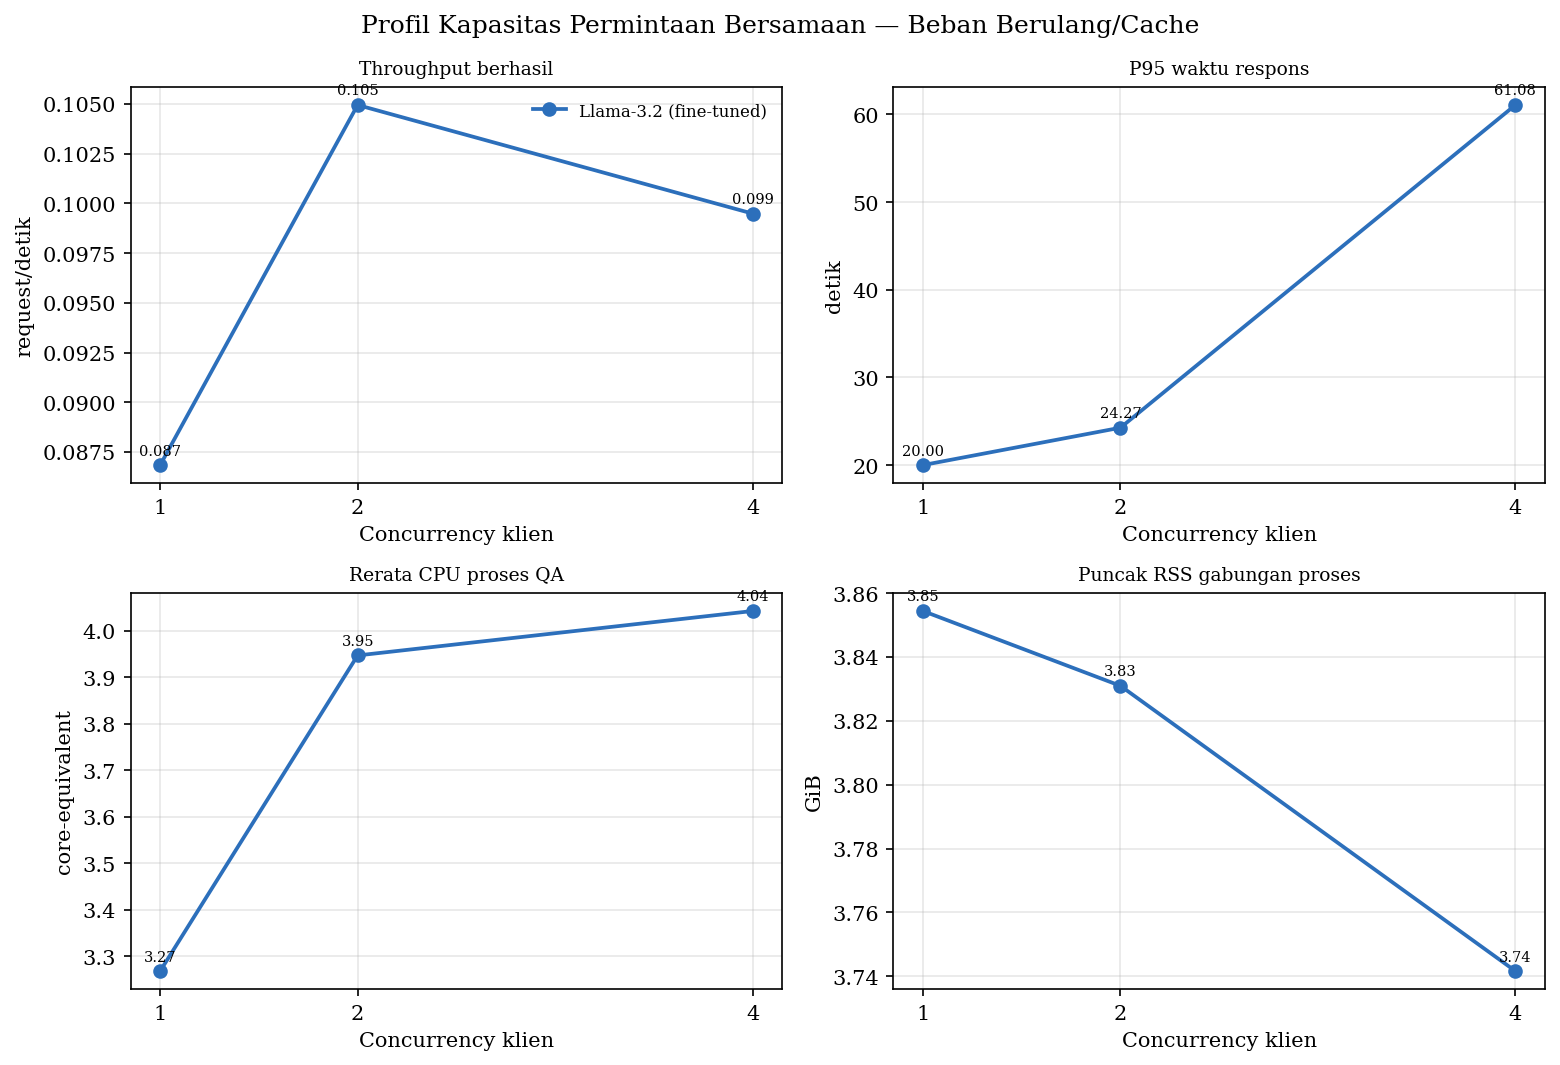

Error rate maksimum profil concurrency: 0.000%
VRAM proses QA tidak divisualisasikan karena sampling per proses belum lengkap.


In [39]:
def fig12b_kapasitas_bersamaan():
    d = capacity_profile.copy()
    wajib = ["model_key", "client_concurrency", "throughput_ok_rps", "response_p95_s",
             "qa_cpu_mean_cores", "peak_process_rss_mb", "error_rate"]
    if d.empty or any(c not in d for c in wajib):
        lewati("fig12b: capacity_profile.csv belum lengkap."); return
    model_order = _urutan_model(d)
    metrik = [
        ("throughput_ok_rps", "Throughput berhasil", "request/detik", "{:.3f}"),
        ("response_p95_s", "P95 waktu respons", "detik", "{:.2f}"),
        ("qa_cpu_mean_cores", "Rerata CPU proses QA", "core-equivalent", "{:.2f}"),
        ("peak_process_rss_mb", "Puncak RSS gabungan proses", "GiB", "{:.2f}"),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.2))
    for ax, (kolom, judul, unit, fmt) in zip(axes.flat, metrik):
        for model in model_order:
            s = d[d["model_key"].astype(str).eq(model)].sort_values("client_concurrency")
            nilai = pd.to_numeric(s[kolom], errors="coerce")
            if kolom == "peak_process_rss_mb":
                nilai = nilai / 1024
            ax.plot(s["client_concurrency"], nilai, marker="o", linewidth=1.8,
                    label=label_model(model), color=warna_model(model))
            for x, y in zip(s["client_concurrency"], nilai):
                if pd.notna(y):
                    ax.annotate(fmt.format(y), (x, y), xytext=(0, 5),
                                textcoords="offset points", ha="center", fontsize=7)
        ax.set_xticks(sorted(d["client_concurrency"].dropna().unique()))
        ax.set_xlabel("Concurrency klien")
        ax.set_ylabel(unit); ax.set_title(judul, fontsize=9)
    axes[0, 0].legend(fontsize=8, frameon=False)
    fig.suptitle("Profil Kapasitas Permintaan Bersamaan — Beban Berulang/Cache")
    plt.tight_layout(); plt.savefig("fig12b_kapasitas_bersamaan.png", bbox_inches="tight"); plt.show()

    error = pd.to_numeric(d["error_rate"], errors="coerce")
    print(f"Error rate maksimum profil concurrency: {error.max():.3%}")
    if "qa_gpu_sampling_complete" in d and not d["qa_gpu_sampling_complete"].astype(str).str.lower().eq("true").all():
        print("VRAM proses QA tidak divisualisasikan karena sampling per proses belum lengkap.")

fig12b_kapasitas_bersamaan()


## 5. Pengujian black-box dan kelengkapan eksekusi


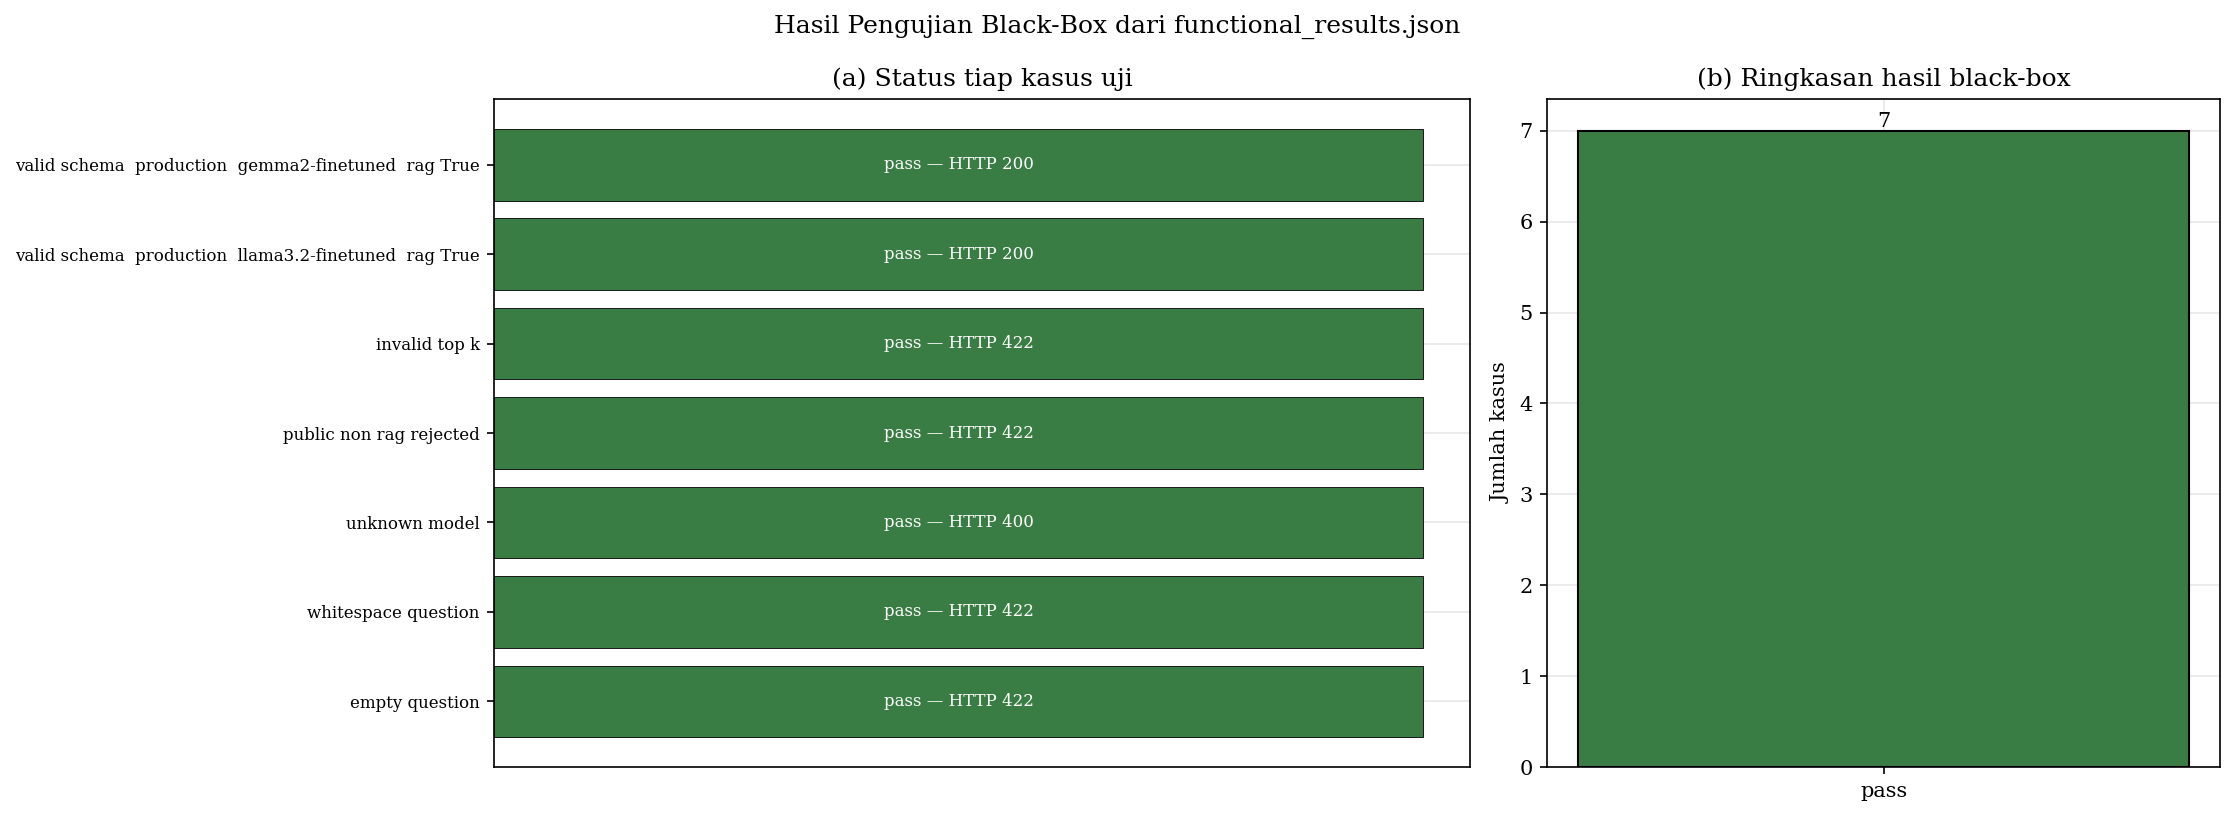

In [40]:
def fig13_blackbox():
    d = pd.DataFrame(functional_results)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.45, 1]})
    ax = axes[0]
    y = np.arange(len(d))
    warna = [C_GREEN if str(s).lower() == "pass" else C_RED for s in d["status"]]
    ax.barh(y, np.ones(len(d)), color=warna, edgecolor="black", linewidth=.4)
    ax.set_yticks(y); ax.set_yticklabels(d["case"].str.replace("_", " "), fontsize=8)
    ax.set_xticks([]); ax.set_xlim(0, 1.05); ax.set_title("(a) Status tiap kasus uji")
    for yi, (status, kode) in enumerate(zip(d["status"], d["status_code"])):
        ax.text(.5, yi, f"{status} — HTTP {kode}", ha="center", va="center", color="white", fontsize=8)

    ax = axes[1]
    ringkas = d["status"].value_counts()
    ax.bar(ringkas.index, ringkas.values,
           color=[C_GREEN if str(x).lower() == "pass" else C_RED for x in ringkas.index], edgecolor="black")
    for x, v in enumerate(ringkas): ax.text(x, v, f"{v:,}", ha="center", va="bottom")
    ax.set_ylabel("Jumlah kasus"); ax.set_title("(b) Ringkasan hasil black-box")
    fig.suptitle("Hasil Pengujian Black-Box dari functional_results.json")
    plt.tight_layout(); plt.savefig("fig13_blackbox.png", bbox_inches="tight"); plt.show()

fig13_blackbox()


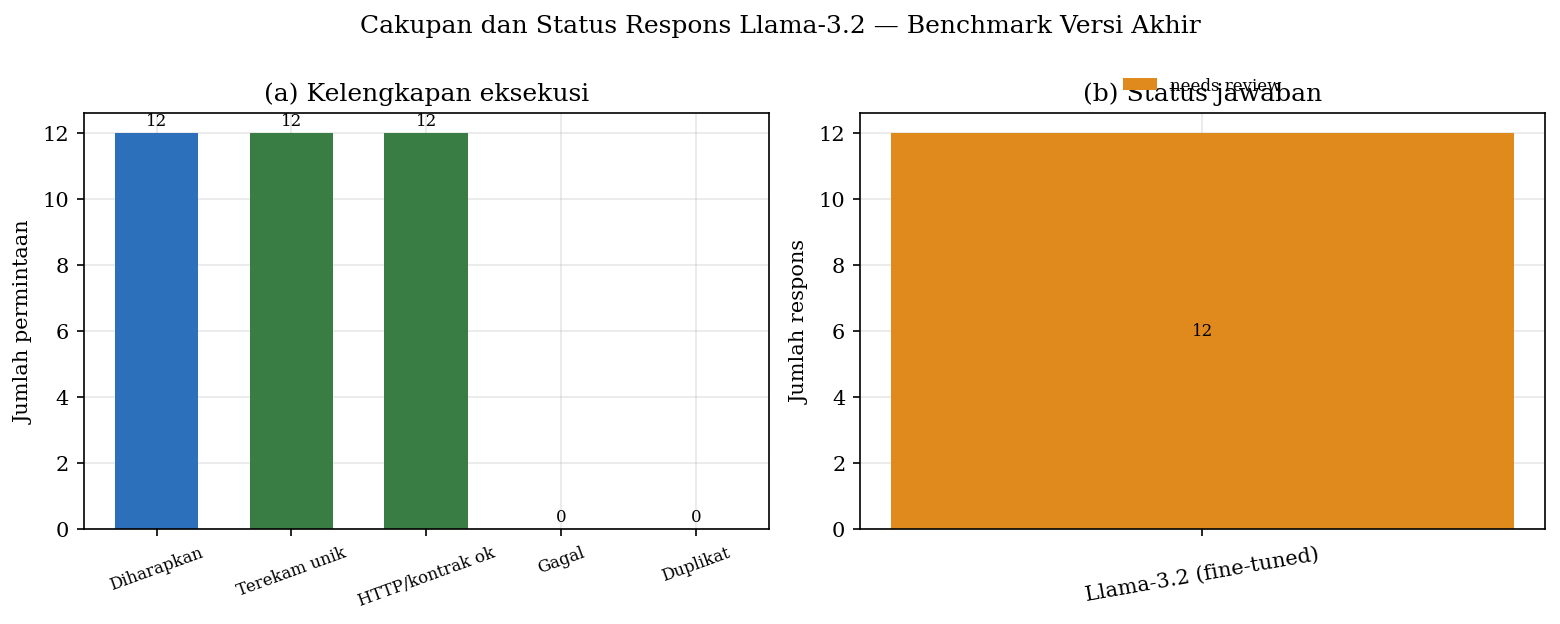

In [41]:
def fig14_coverage_pengujian():
    d = performance.copy()
    kunci = ["model_key", "question_id", "repeat"]
    expected = len(perf_environment["test_questions"]) * int(perf_environment["repeat_per_question"])
    recorded = int(d.drop_duplicates(kunci).shape[0])
    ok = int(d["status"].astype(str).str.lower().eq("ok").sum())
    failed = int(len(d) - ok)
    duplicates = int(d.duplicated(kunci).sum())

    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
    ax = axes[0]
    labels = ["Diharapkan", "Terekam unik", "HTTP/kontrak ok", "Gagal", "Duplikat"]
    nilai = [expected, recorded, ok, failed, duplicates]
    colors = [C_BLUE, C_GREEN, C_GREEN, C_RED, C_ORANGE]
    bars = ax.bar(labels, nilai, color=colors, width=.62)
    ax.bar_label(bars, labels=[f"{v:,}" for v in nilai], padding=2, fontsize=8)
    ax.set_ylabel("Jumlah permintaan")
    ax.set_title("(a) Kelengkapan eksekusi")
    ax.tick_params(axis="x", labelrotation=20, labelsize=8)

    ax = axes[1]
    status = pd.crosstab(d["model_key"], d["answer_status"]).reindex(_urutan_model(d), fill_value=0)
    status_colors = {"basic_checks_passed": C_GREEN, "needs_review": C_ORANGE,
                     "no_evidence": C_RED}
    bottom = np.zeros(len(status))
    x = np.arange(len(status))
    for kolom in status.columns:
        nilai_status = status[kolom].to_numpy(float)
        bars = ax.bar(x, nilai_status, bottom=bottom,
                      label=kolom.replace("_", " "),
                      color=status_colors.get(str(kolom), C_GRAY))
        for bar, v, dasar in zip(bars, nilai_status, bottom):
            if v > 0:
                ax.text(bar.get_x()+bar.get_width()/2, dasar+v/2, f"{int(v)}",
                        ha="center", va="center", fontsize=8)
        bottom += nilai_status
    ax.set_xticks(x); ax.set_xticklabels([label_model(m) for m in status.index], rotation=10)
    ax.set_ylabel("Jumlah respons")
    ax.set_title("(b) Status jawaban")
    ax.legend(fontsize=8, frameon=False, loc="lower center",
              bbox_to_anchor=(.5, 1.01), ncol=max(1, len(status.columns)))
    fig.suptitle("Cakupan dan Status Respons Llama-3.2 — Benchmark Versi Akhir")
    plt.tight_layout(); plt.savefig("fig14_coverage_pengujian.png", bbox_inches="tight"); plt.show()

fig14_coverage_pengujian()


## 6. Perencanaan adopsi BPS

Grafik berikut membaca run terbaru yang lengkap pada `Hasil/tujuan3/adopsi-bps`.
Kebutuhan operasional, profil concurrency, dan pengembangan model hanya menampilkan
Llama-3.2 dari hasil terbaru. Angka
CPU berbentuk *core-equivalent* pada perangkat uji; jalur layanan independen bukan jumlah
GPU. RAM hanya ditampilkan untuk concurrency yang benar-benar mempunyai bukti pengukuran,
sedangkan VRAM, proyeksi disk lengkap, dan besaran lain yang belum tersedia tetap kosong.

Proyeksi pelatihan berlaku hanya dengan asumsi konfigurasi yang sama. Beban pembuatan
dataset merupakan asumsi perencanaan. Grafik cakupan bukti memperlihatkan dengan eksplisit
komponen yang sudah terukur, baru tercatat sebagian, atau belum diukur.


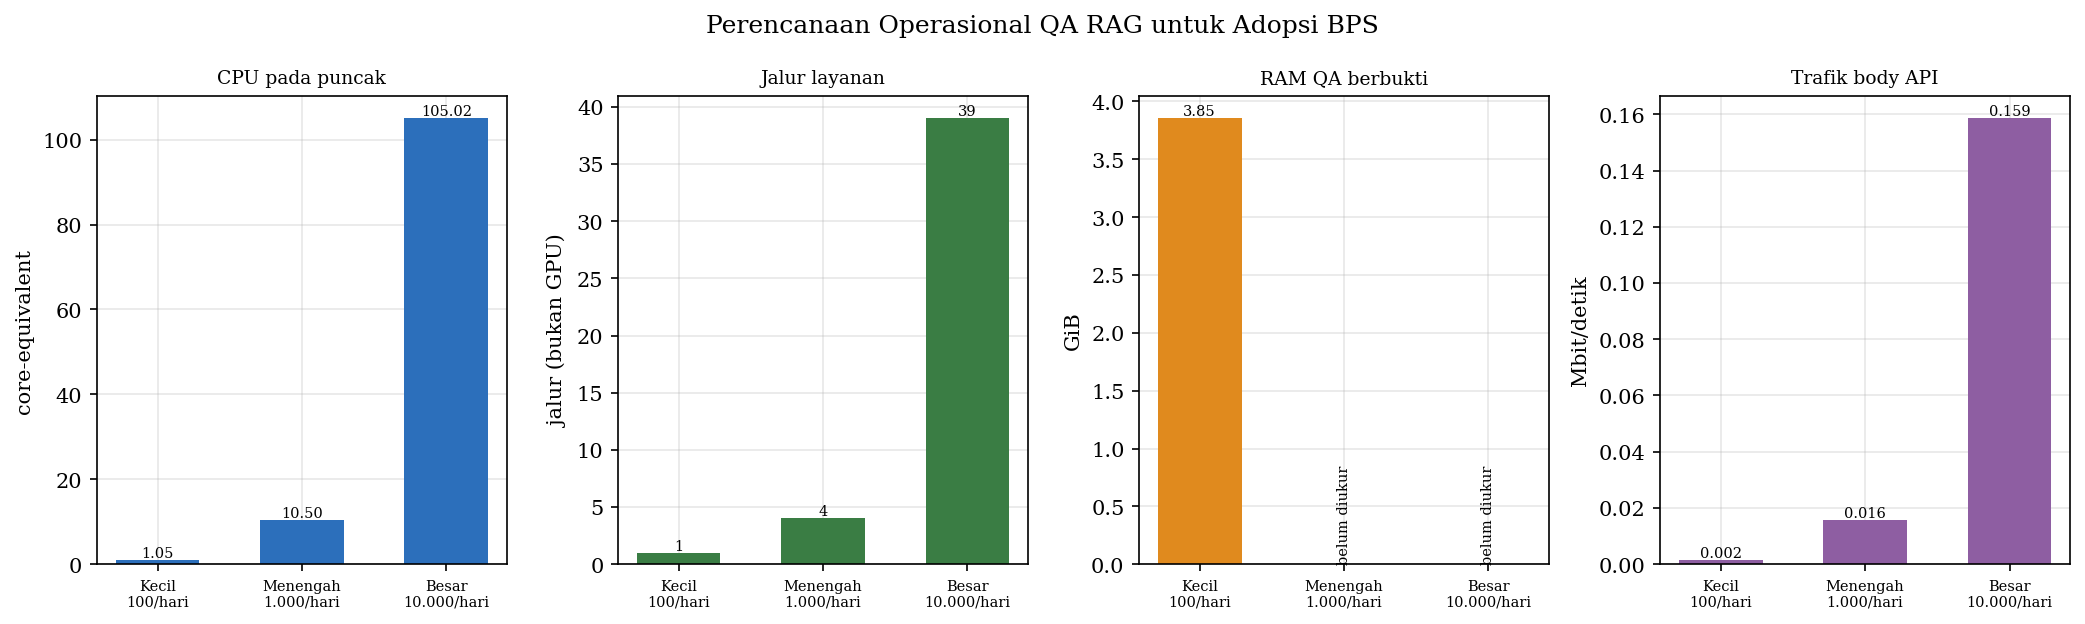

In [42]:
def fig15_adopsi_operasional():
    d = adopsi_operasional.copy()
    wajib = ["scenario", "requests_per_day", "estimated_cpu_core_equivalents_at_peak",
             "estimated_independent_service_lanes_NOT_GPU_count",
             "ram_qa_gib_with_explicit_margin",
             "estimated_api_body_mbps_at_peak_excludes_protocol_and_pdf"]
    if d.empty or any(c not in d for c in wajib):
        lewati("fig15: keluaran kebutuhan operasional terbaru belum lengkap."); return
    labels = [f"{str(s).title()}\n{int(r):,}/hari".replace(",", ".")
              for s, r in zip(d["scenario"], d["requests_per_day"])]
    x = np.arange(len(d))
    fig, axes = plt.subplots(1, 4, figsize=(14, 4.2))

    panels = [
        ("estimated_cpu_core_equivalents_at_peak", "CPU pada puncak", "core-equivalent", C_BLUE, "{:.2f}"),
        ("estimated_independent_service_lanes_NOT_GPU_count", "Jalur layanan", "jalur (bukan GPU)", C_GREEN, "{:.0f}"),
        ("ram_qa_gib_with_explicit_margin", "RAM QA berbukti", "GiB", C_ORANGE, "{:.2f}"),
        ("estimated_api_body_mbps_at_peak_excludes_protocol_and_pdf", "Trafik body API", "Mbit/detik", C_PURPLE, "{:.3f}"),
    ]
    for ax, (kolom, judul, unit, warna, fmt) in zip(axes, panels):
        nilai = pd.to_numeric(d[kolom], errors="coerce")
        bars = ax.bar(x, nilai.fillna(0), color=warna, width=.58)
        for bar, v in zip(bars, nilai):
            teks = "belum diukur" if pd.isna(v) else fmt.format(v)
            ax.text(bar.get_x()+bar.get_width()/2, (0 if pd.isna(v) else v), teks,
                    ha="center", va="bottom", fontsize=7, rotation=90 if pd.isna(v) else 0)
        ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=7)
        ax.set_ylabel(unit); ax.set_title(judul, fontsize=9)
    fig.suptitle("Perencanaan Operasional QA RAG untuk Adopsi BPS")
    plt.tight_layout(); plt.savefig("fig15_adopsi_operasional.png", bbox_inches="tight"); plt.show()

fig15_adopsi_operasional()


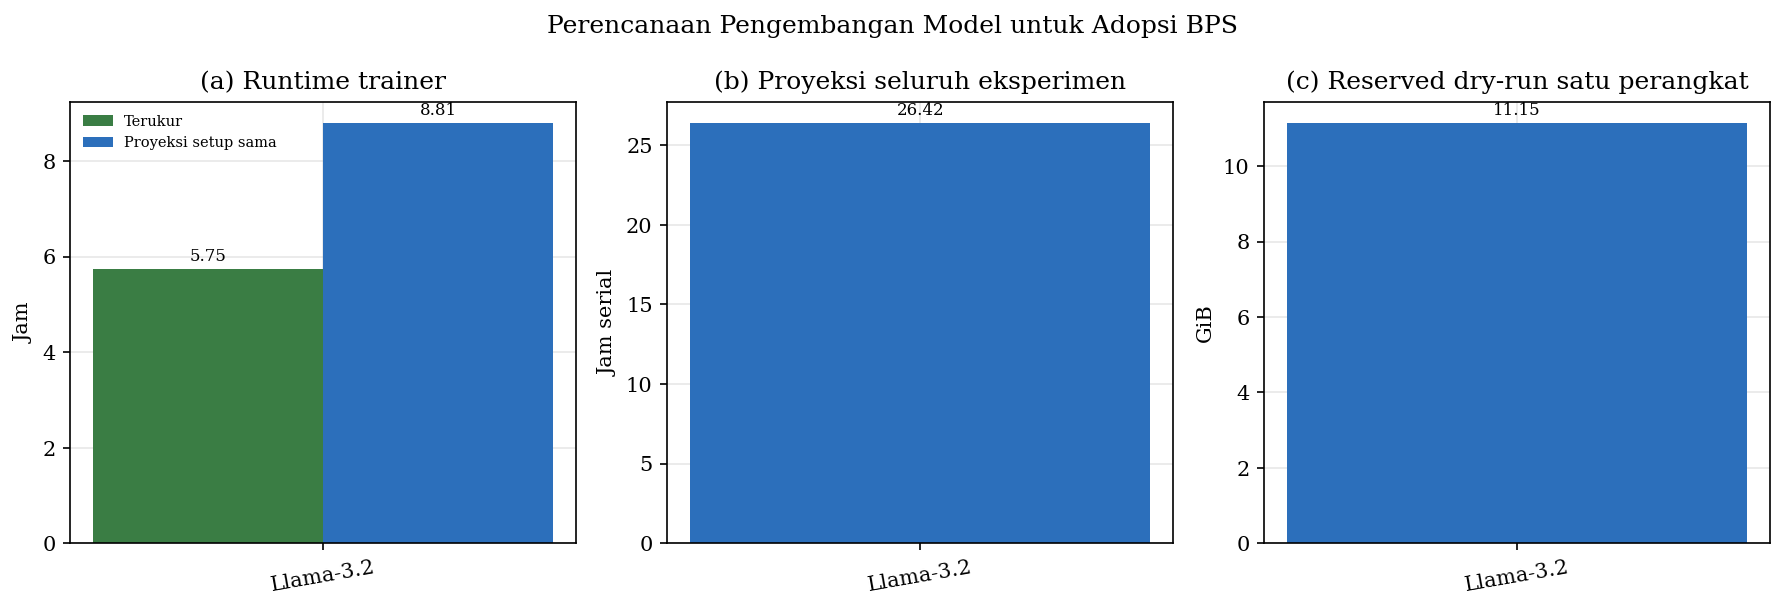

In [43]:
def fig16_adopsi_pengembangan():
    d = adopsi_pengembangan.copy()
    wajib = ["model", "measured_trainer_runtime_hours", "projected_trainer_hours_same_setup",
             "projected_serial_experiment_hours", "dry_run_reserved_gib_single_device"]
    if d.empty or any(c not in d for c in wajib):
        lewati("fig16: keluaran kebutuhan pengembangan belum lengkap."); return
    order = [m for m in [ARSITEKTUR_UTAMA] if m in set(d["model"])]
    order += sorted(set(d["model"]) - set(order))
    d = d.set_index("model").reindex(order)
    labels = [label_model(m) for m in d.index]
    colors = [warna_model(m) for m in d.index]
    x = np.arange(len(d)); lebar = .34
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.1))

    ax = axes[0]
    aktual = d["measured_trainer_runtime_hours"].to_numpy(float)
    proyeksi = d["projected_trainer_hours_same_setup"].to_numpy(float)
    b1 = ax.bar(x-lebar/2, aktual, lebar, label="Terukur", color=C_GREEN)
    b2 = ax.bar(x+lebar/2, proyeksi, lebar, label="Proyeksi setup sama", color=C_BLUE)
    ax.bar_label(b1, labels=[f"{v:.2f}" for v in aktual], padding=2, fontsize=8)
    ax.bar_label(b2, labels=[f"{v:.2f}" for v in proyeksi], padding=2, fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=10)
    ax.set_ylabel("Jam"); ax.set_title("(a) Runtime trainer")
    ax.legend(fontsize=7, frameon=False)

    ax = axes[1]
    nilai = d["projected_serial_experiment_hours"].to_numpy(float)
    bars = ax.bar(labels, nilai, color=colors, width=.58)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in nilai], padding=2, fontsize=8)
    ax.set_ylabel("Jam serial"); ax.set_title("(b) Proyeksi seluruh eksperimen")
    ax.tick_params(axis="x", labelrotation=10)

    ax = axes[2]
    memori = d["dry_run_reserved_gib_single_device"].to_numpy(float)
    bars = ax.bar(labels, memori, color=colors, width=.58)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in memori], padding=2, fontsize=8)
    ax.set_ylabel("GiB"); ax.set_title("(c) Reserved dry-run satu perangkat")
    ax.tick_params(axis="x", labelrotation=10)
    fig.suptitle("Perencanaan Pengembangan Model untuk Adopsi BPS")
    plt.tight_layout(); plt.savefig("fig16_adopsi_pengembangan.png", bbox_inches="tight"); plt.show()

fig16_adopsi_pengembangan()


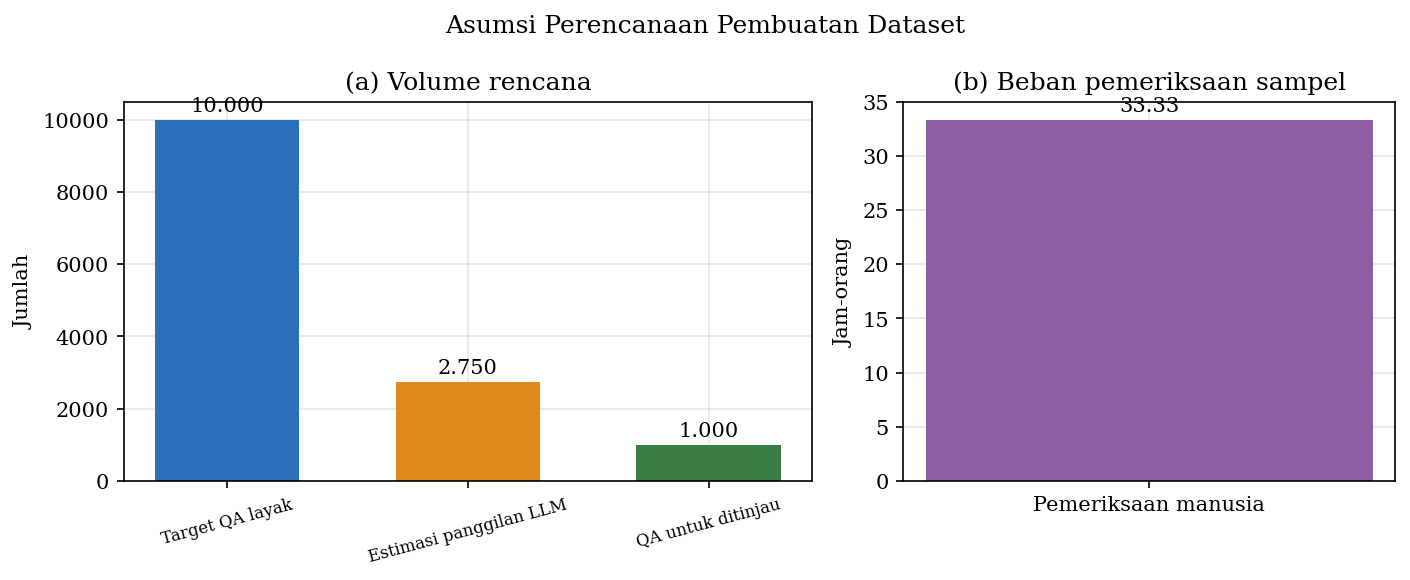

In [44]:
def fig17_adopsi_dataset():
    d = adopsi_dataset.copy()
    if d.empty:
        lewati("fig17: keluaran beban pembuatan dataset belum tersedia."); return
    row = d.iloc[0]
    keys = ["accepted_qa_target", "estimated_calls_including_extra",
            "qa_to_review_under_sampling_assumption"]
    if any(k not in d or pd.isna(row[k]) for k in keys):
        lewati("fig17: hitungan utama beban dataset belum lengkap."); return

    fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.9), gridspec_kw={"width_ratios": [1.4, 1]})
    ax = axes[0]
    labels = ["Target QA layak", "Estimasi panggilan LLM", "QA untuk ditinjau"]
    nilai = [float(row[k]) for k in keys]
    bars = ax.bar(labels, nilai, color=[C_BLUE, C_ORANGE, C_GREEN], width=.6)
    ax.bar_label(bars, labels=[f"{v:,.0f}".replace(",", ".") for v in nilai], padding=2)
    ax.set_ylabel("Jumlah"); ax.set_title("(a) Volume rencana")
    ax.tick_params(axis="x", labelrotation=15, labelsize=8)

    ax = axes[1]
    jam = pd.to_numeric(pd.Series([row.get("review_person_hours")]), errors="coerce").iloc[0]
    if pd.notna(jam):
        bars = ax.bar(["Pemeriksaan manusia"], [jam], color=C_PURPLE, width=.48)
        ax.bar_label(bars, labels=[f"{jam:.2f}"], padding=2)
    ax.set_ylabel("Jam-orang"); ax.set_title("(b) Beban pemeriksaan sampel")
    fig.suptitle("Asumsi Perencanaan Pembuatan Dataset")
    plt.tight_layout(); plt.savefig("fig17_adopsi_dataset.png", bbox_inches="tight"); plt.show()

fig17_adopsi_dataset()


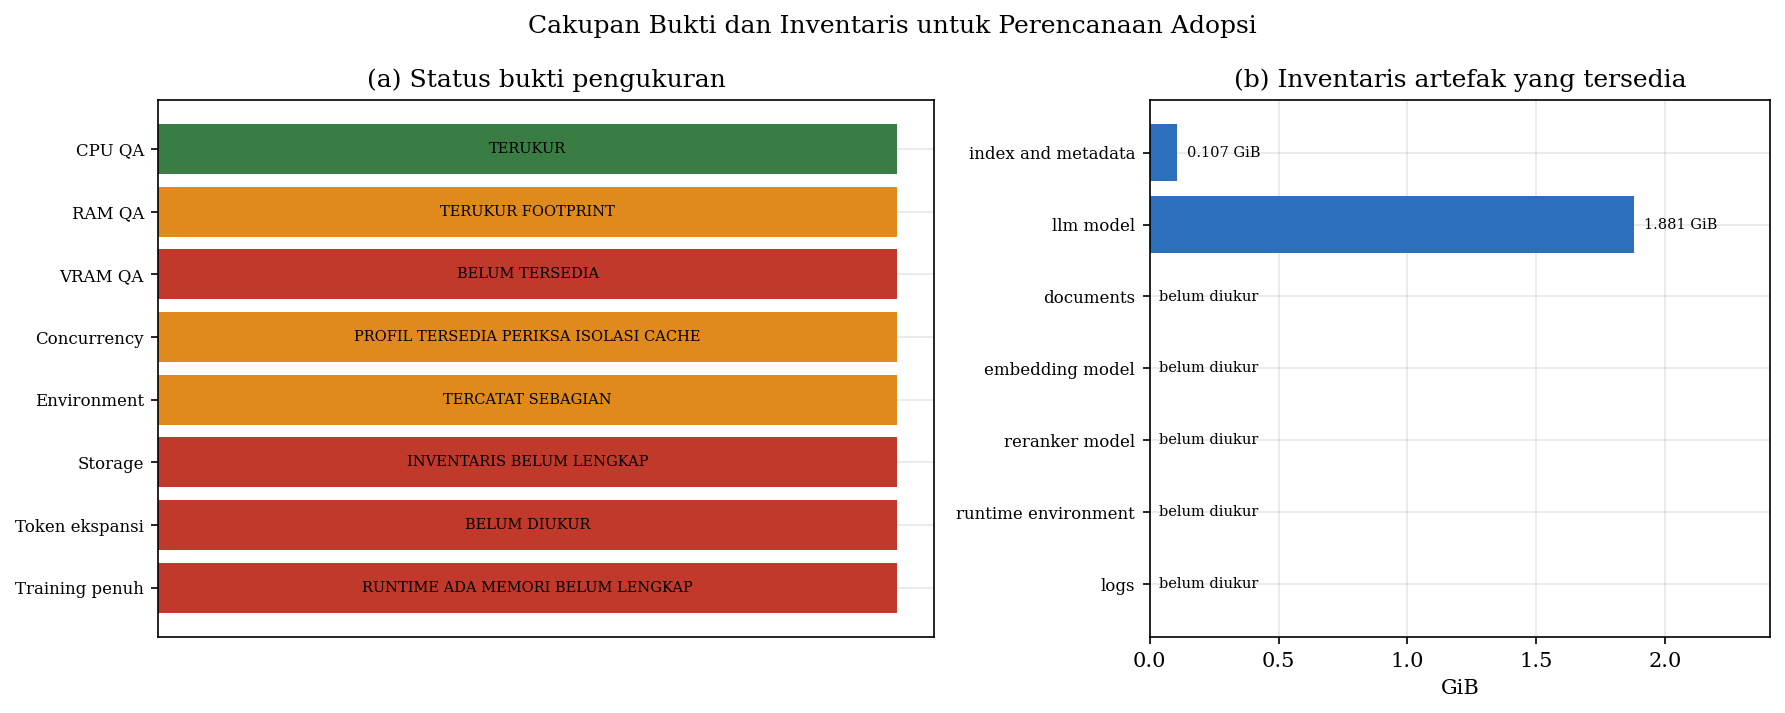

In [45]:
def fig18_cakupan_bukti_adopsi():
    bukti = adopsi_bukti.copy()
    inv = adopsi_inventaris.copy()
    if bukti.empty or inv.empty:
        lewati("fig18: cakupan bukti atau inventaris artefak belum tersedia."); return

    def warna_status(status):
        teks = str(status).upper()
        if "BELUM" in teks:
            return C_RED
        if "SEBAGIAN" in teks or "PERIKSA" in teks or "FOOTPRINT" in teks:
            return C_ORANGE
        return C_GREEN

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
    ax = axes[0]
    y = np.arange(len(bukti))
    bars = ax.barh(y, np.ones(len(bukti)), color=[warna_status(s) for s in bukti["status"]])
    ax.set_yticks(y); ax.set_yticklabels(bukti["component"], fontsize=8)
    ax.set_xticks([]); ax.invert_yaxis(); ax.set_title("(a) Status bukti pengukuran")
    for bar, status in zip(bars, bukti["status"]):
        ax.text(.5, bar.get_y()+bar.get_height()/2, str(status).replace("_", " "),
                ha="center", va="center", fontsize=7)

    ax = axes[1]
    ukuran = pd.to_numeric(inv["bytes"], errors="coerce") / 2**30
    y = np.arange(len(inv))
    bars = ax.barh(y, ukuran.fillna(0), color=[C_BLUE if pd.notna(v) else C_GRAY for v in ukuran])
    ax.set_yticks(y); ax.set_yticklabels(inv["component"].str.replace("_", " "), fontsize=8)
    ax.invert_yaxis(); ax.set_xlabel("GiB"); ax.set_title("(b) Inventaris artefak yang tersedia")
    batas = max(float(ukuran.max(skipna=True) or 0), .01)
    for bar, v in zip(bars, ukuran):
        teks = "belum diukur" if pd.isna(v) else f"{v:.3f} GiB"
        ax.text((0 if pd.isna(v) else v) + batas*.02,
                bar.get_y()+bar.get_height()/2, teks, va="center", fontsize=7)
    ax.set_xlim(0, batas*1.28)
    fig.suptitle("Cakupan Bukti dan Inventaris untuk Perencanaan Adopsi")
    plt.tight_layout(); plt.savefig("fig18_cakupan_bukti_adopsi.png", bbox_inches="tight"); plt.show()

fig18_cakupan_bukti_adopsi()
